In [122]:
# Import Dependencies
import sys
from pathlib import Path
import os
import numpy as np
import pandas as pd
import json

# Ignore warnings to have clean cell outputs
import warnings
warnings.filterwarnings("ignore")

In [123]:
# Get the current working directory (where the notebook is running)
base_dir = Path.cwd()

project_root = base_dir.parent

In [124]:
import sys
import os

# Navigate relative to the current working directory
sys.path.append(os.path.abspath(project_root / 'src'))

import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'serif'
from matplotlib import font_manager
font_manager.fontManager.addfont(project_root / 'data' / 'Times New Roman.ttf')
font_manager.fontManager.addfont(project_root / 'data' / 'Times New Roman - Bold.ttf')
plt.rcParams['font.serif'] = ['Times New Roman']
import matplotlib.gridspec as gridspec

plt.rcParams['mathtext.fontset'] = 'custom' # Use custom font settings
plt.rcParams['mathtext.sf'] = 'Times New Roman:italic' # Sans-serif font (if needed, often not for math)
plt.rcParams['mathtext.rm'] = 'Times New Roman:normal' # Roman (standard text) font
plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'   # Bold font
plt.rcParams['mathtext.it'] = 'Times New Roman:italic' # Italic font

import seaborn as sns
from itertools import accumulate

import numpy as np
import pandas as pd
from sixdman.core.network import Network
from sixdman.core.post_process import analyse_result
from sixdman.utils.paths import get_project_root

import warnings
warnings.filterwarnings("ignore")

### *Define Paths*

In [125]:
results_noBypass_dir = project_root / "results" / "MAN157_400G_CAGR_0.4" / "NoBypass"
results_noBypass_dir.mkdir(parents=True, exist_ok=True)

results_HL3Bypassed_dir = project_root / "results" / "MAN157_400G_CAGR_0.4" / "HL3Bypassed"
results_HL3Bypassed_dir.mkdir(parents=True, exist_ok=True)

save_directory = project_root / "results" / "JOCN_Plots"
save_directory.mkdir(parents=True, exist_ok=True)

### *Define Network Instances*

In [126]:
# Initialize network
network_noBypass = Network(topology_name = 'MAN157')

# Load topology from .mat file
network_noBypass.load_topology(filepath = project_root / 'data' / 'MAN157Nodes.mat', matrixName ='MAN157Nodes')

# Set hierarchical levels
hl_dict = network_noBypass.define_hierarchy(
    HL1_standalone = [1, 5],
    HL2_standalone = [0, 2, 3, 4],
    HL3_standalone = list(range(6, 39)),
    HL4_standalone = list(range(39, 157))
)

In [127]:
# Initialize network
network_HL3Bypassed = Network(topology_name = 'MAN157')

# Load topology from .mat file
network_HL3Bypassed.load_topology(filepath = project_root / 'data' / 'MAN157Nodes.mat', matrixName ='MAN157Nodes')

# Set hierarchical levels
hl_dict = network_HL3Bypassed.define_hierarchy(
    HL1_standalone = [1, 5],
    HL2_standalone = [0, 2, 3, 4],
    HL3_standalone = list(range(6, 39)),
    HL4_standalone = list(range(6, 39)) + list(range(39, 157)), 
    HL4_colocated = [0, 2, 3, 4] + [1, 5]
)

In [128]:
processing_level_list_noBypass = [4, 3, 2]
processing_level_list_HL3Bypassed = [4, 2]
total_simulation_time = 10
channel_spacing = 75

### *Load Saved Results*

In [129]:
analyse_noBypass = analyse_result(network_instance = network_noBypass, 
                                  period_time = total_simulation_time, 
                                  processing_level_list = [4, 3, 2], 
                                  results_directory = results_noBypass_dir, 
                                  save_directory = results_noBypass_dir)
analyse_HL3Bypassed = analyse_result(network_instance = network_HL3Bypassed, 
                                     period_time = total_simulation_time,  
                                     processing_level_list = [4, 2], 
                                     results_directory = results_HL3Bypassed_dir, 
                                     save_directory = results_HL3Bypassed_dir)

In [130]:
analyse_noBypass._load_data()
analyse_HL3Bypassed._load_data()
splitter = [166, 47, 7]

#### *Define a Function for Safe Relative Difference Calculation*

In [131]:
def safe_percent_diff(a, b):
    with np.errstate(divide='ignore', invalid='ignore'):
        percent = np.where(a != 0, (b - a) / a * 100,
                           np.where(b != 0, np.inf, 0))  # ∞ if b≠0 and a=0, else 0
    return percent

#### *Define a Function for Sort by Link Distances*

In [132]:
def sort_by_weight(array_not_sorted, processing_level_list):
    
    array_sorted = np.empty(shape = (array_not_sorted.shape[0], 0))
    
    for hierarchy_level in processing_level_list:
        sub_graph_HL, _ = network_noBypass.compute_hierarchy_subgraph(hierarchy_level, 
                                                                      minimum_hierarchy_level = processing_level_list[0])
        HL_subnet_links = np.array(list(sub_graph_HL.edges(data = 'weight')))
        mask = np.any(np.all(network_noBypass.all_links[:, None] == HL_subnet_links, axis = 2), axis=1)
        HL_links_indices_HL = np.where(mask)[0]
        idx_sort = np.argsort(HL_subnet_links[:, 2])  
        HL_links_indices_HL_sorted = HL_links_indices_HL[idx_sort]
        HL_selected_values = array_not_sorted[:, HL_links_indices_HL_sorted]
        
        array_sorted = np.hstack((
			array_sorted,
			HL_selected_values
		))

    return array_sorted

### *Cumulative Fiber Pair Usage*

In [133]:
# Cumulative Fiber Pair usage in km
km_total_noBypass = 0
fp_total_noBypass = 0

for hierarchy_level in processing_level_list_noBypass:
    km = analyse_noBypass.link_data[f"HL{hierarchy_level}"]['Total_effective_FP_new_annual']
    fp = np.sum(analyse_noBypass.link_data[f"HL{hierarchy_level}"]['HL_FPNum'], axis = 1)
    km_total_noBypass += km
    fp_total_noBypass += fp

km_total_HL3Bypassed = 0
fp_total_HL3Bypassed = 0

for hierarchy_level in processing_level_list_HL3Bypassed:
    km = analyse_HL3Bypassed.link_data[f"HL{hierarchy_level}"]['Total_effective_FP_new_annual']
    fp = np.sum(analyse_HL3Bypassed.link_data[f"HL{hierarchy_level}"]['HL_FPNum'], axis = 1)
    km_total_HL3Bypassed += km
    fp_total_HL3Bypassed += fp

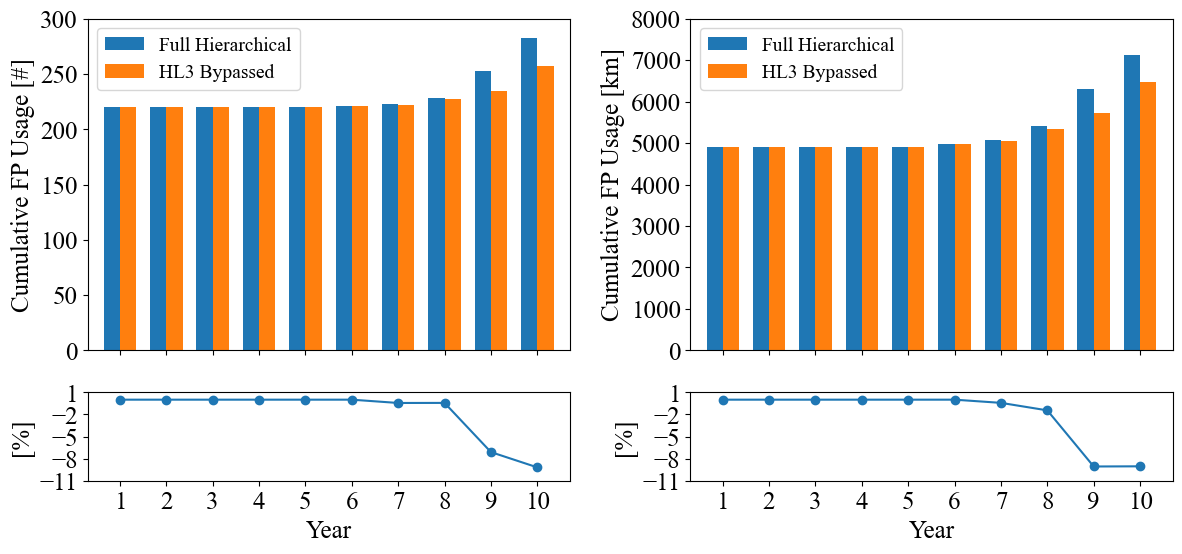

In [134]:
# Values per year
fig = plt.figure(figsize=(14, 6))
gs = gridspec.GridSpec(2, 2, height_ratios=[1.5, 0.4], wspace=0.25)

# Create all subplots
axs = [fig.add_subplot(gs[0, 0]),
       fig.add_subplot(gs[0, 1]), 
       fig.add_subplot(gs[1, 0]),
       fig.add_subplot(gs[1, 1]), 
       ]

year = np.arange(1, total_simulation_time + 1)
width = 0.35

axs[0].bar(year - width / 2, fp_total_noBypass, label = 'Full Hierarchical', width = width)
axs[0].bar(year + width / 2, fp_total_HL3Bypassed, label = 'HL3 Bypassed', width = width)

axs[0].set_ylabel('Cumulative FP Usage [#]', fontsize = 18,)
axs[0].tick_params(axis = 'y', labelsize = 18)
axs[0].set_yticks(np.arange(0, 301, 50))
# axs[0].set_xlabel('Year', fontsize = 18)
axs[0].set_xticks(year)
axs[0].set_xticklabels([])
axs[0].tick_params(axis = 'x', labelsize = 18)
axs[0].legend(loc='upper left', fontsize = 14) 

axs[2].plot(year, safe_percent_diff(fp_total_noBypass, fp_total_HL3Bypassed), '-o', color = 'C0')
axs[2].set_ylabel('[%]', fontsize = 18)
axs[2].tick_params(axis = 'x', labelsize = 18)
axs[2].set_xticks(year)
axs[2].set_xlabel('Year', fontsize = 18)
axs[2].tick_params(axis='y', labelsize = 18)
axs[2].set_yticks(np.arange(-11, 2, 3))


axs[1].bar(year - width / 2, km_total_noBypass, label = 'Full Hierarchical', width = width)
axs[1].bar(year + width / 2, km_total_HL3Bypassed, label = 'HL3 Bypassed', width = width)
axs[1].set_ylabel('Cumulative FP Usage [km]', fontsize = 18,)
axs[1].tick_params(axis = 'y', labelsize = 18)
axs[1].set_yticks(np.arange(0, 8001, 1000))
axs[1].set_xticks(year)
axs[1].set_xticklabels([])
axs[1].tick_params(axis = 'x', labelsize = 18)
axs[1].legend(loc='upper left', fontsize = 14) 

axs[3].plot(year, safe_percent_diff(km_total_noBypass, km_total_HL3Bypassed), '-o', color = 'C0')
axs[3].set_ylabel('[%]', fontsize = 18)
axs[3].tick_params(axis = 'x', labelsize = 18)
axs[3].set_xticks(year)
axs[3].set_xlabel('Year', fontsize = 18)
axs[3].tick_params(axis='y', labelsize = 18)
axs[3].set_yticks(np.arange(-11, 2, 3))

for ax in axs:
    ax.set_xlim(year.min() - 2 * width, year.max() + 2 * width)
    
plt.tight_layout()  # Leave space for title
# plt.savefig(save_directory / f"{network_noBypass.topology_name}_FP_Usage_Cum.png", format='png', dpi=600, bbox_inches='tight')
plt.show()

In [135]:
safe_percent_diff(fp_total_noBypass, fp_total_HL3Bypassed)

array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        , -0.44843049, -0.43859649, -7.11462451, -9.18727915])

In [136]:
safe_percent_diff(km_total_noBypass, km_total_HL3Bypassed)

array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        , -0.433961  , -1.4519197 , -9.06871859, -9.0444515 ])

#### *Sort FP Values by Sub-Networks*

In [137]:
link_state_HL_partisioned_noBypass = np.empty(shape = (total_simulation_time, 0))
for hierarchy_level in processing_level_list_noBypass:

		sub_graph_HL, _ = network_noBypass.compute_hierarchy_subgraph(hierarchy_level, minimum_hierarchy_level = 4)
		HL_subnet_links = np.array(list(sub_graph_HL.edges(data = 'weight')))
		idx_sort = np.argsort(HL_subnet_links[:, 2])        
		HL_FPNum_sorted = analyse_noBypass.link_data[f"HL{hierarchy_level}"]['HL_FPNum'][:, idx_sort]


		link_state_HL_partisioned_noBypass = np.hstack((
			link_state_HL_partisioned_noBypass,
			HL_FPNum_sorted
		))

In [138]:
link_state_HL_partisioned_HL3Bypassed = np.empty(shape = (total_simulation_time, 0))
for hierarchy_level in processing_level_list_HL3Bypassed:
    
    if hierarchy_level == 4:
        sub_graph_HL, _ = network_noBypass.compute_hierarchy_subgraph(4, minimum_hierarchy_level = 4)
        HL_subnet_links = np.array(list(sub_graph_HL.edges(data = 'weight')))
        idx_sort = np.argsort(HL_subnet_links[:, 2])
                
        HL_FPNum_sorted = analyse_HL3Bypassed.link_data[f"HL{hierarchy_level}"]['HL_FPNum'][:, idx_sort]
        
        link_state_HL_partisioned_HL3Bypassed = np.hstack((
			link_state_HL_partisioned_HL3Bypassed,
			HL_FPNum_sorted
		))
  
        sub_graph_HL, _ = network_noBypass.compute_hierarchy_subgraph(3, minimum_hierarchy_level = 4)
        HL_subnet_links = np.array(list(sub_graph_HL.edges(data = 'weight')))
        idx_sort = np.argsort(HL_subnet_links[:, 2])
                
        HL_FPNum_sorted = analyse_HL3Bypassed.link_data[f"HL{hierarchy_level}"]['HL_FPNum'][:, idx_sort]
        
        link_state_HL_partisioned_HL3Bypassed = np.hstack((
			link_state_HL_partisioned_HL3Bypassed,
			HL_FPNum_sorted
		))
    else:
        sub_graph_HL, _ = network_noBypass.compute_hierarchy_subgraph(hierarchy_level, minimum_hierarchy_level = 4)
        HL_subnet_links = np.array(list(sub_graph_HL.edges(data = 'weight')))
        idx_sort = np.argsort(HL_subnet_links[:, 2])
        
        HL_FPNum_sorted = analyse_HL3Bypassed.link_data[f"HL{hierarchy_level}"]['HL_FPNum'][:, idx_sort]
        
        link_state_HL_partisioned_HL3Bypassed = np.hstack((
			link_state_HL_partisioned_HL3Bypassed,
			HL_FPNum_sorted
		))

#### *Plot FP Usage Difference Between Scenarios*

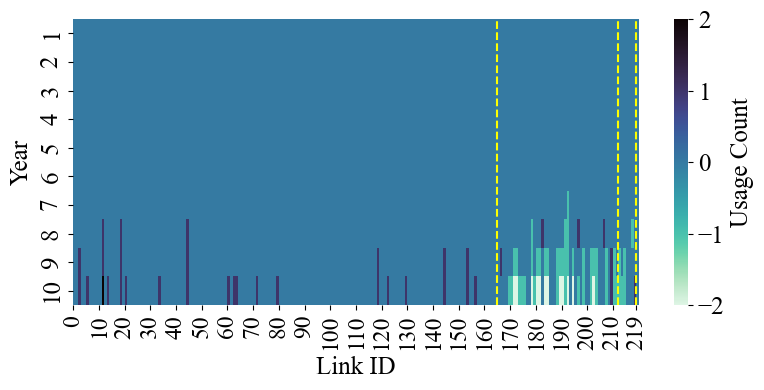

In [139]:
fp_sorted_noBypass = link_state_HL_partisioned_noBypass
fp_sorted_HL3Bypassed = link_state_HL_partisioned_HL3Bypassed
delta = fp_sorted_HL3Bypassed  - fp_sorted_noBypass

fig, axs = plt.subplots(figsize = (8, 4))
sns.heatmap(delta, cmap='mako_r', center=0, ax = axs)
axs.set_xlabel('Link ID', fontsize = 18)
axs.set_ylabel('Year', fontsize = 18)
axs.tick_params(axis = 'x', labelsize = 17)
axs.tick_params(axis = 'y', labelsize = 18)
axs.set_yticks(ticks=np.arange(10) + 0.5, labels=np.arange(1, 11))
axs.set_xticks(np.append(np.arange(0, len(network_noBypass.all_links), 10), len(network_noBypass.all_links) - 1))
axs.set_xticklabels(np.append(np.arange(0, len(network_noBypass.all_links), 10), len(network_noBypass.all_links) - 1))

cbar = axs.collections[0].colorbar
cbar.ax.set_yticks([-2, -1, 0, 1, 2])
cbar.ax.tick_params(labelsize = 18) 
cbar.set_label("Usage Count", fontsize = 18)
    
splitter_converted = list(accumulate(splitter))
for i in range(len(splitter_converted)):
    axs.axvline(x=splitter_converted[i] - 1, color='yellow', linestyle='--', linewidth = 1.5)

plt.tight_layout()
# plt.savefig(save_directory / f"{network_noBypass.topology_name}_Delta_Fiber_Pairs.png", format='png', dpi=600, bbox_inches='tight')
plt.show()



### *Band Degree*

In [140]:
deg_c_annual_noBypass = analyse_noBypass.link_data[f"HL2"]['num_link_CBand_annual'].sum(axis = 1)
deg_superc_annual_noBypass = analyse_noBypass.link_data[f"HL2"]['num_link_SupCBand_annual'].sum(axis = 1)
deg_l_annual_noBypass = analyse_noBypass.link_data[f"HL2"]['num_link_LBand_annual'].sum(axis = 1)

deg_c_annual_HL3Bypassed = analyse_HL3Bypassed.link_data[f"HL2"]['num_link_CBand_annual'].sum(axis = 1)
deg_superc_annual_HL3Bypassed = analyse_HL3Bypassed.link_data[f"HL2"]['num_link_SupCBand_annual'].sum(axis = 1)
deg_l_annual_HL3Bypassed = analyse_HL3Bypassed.link_data[f"HL2"]['num_link_LBand_annual'].sum(axis = 1)

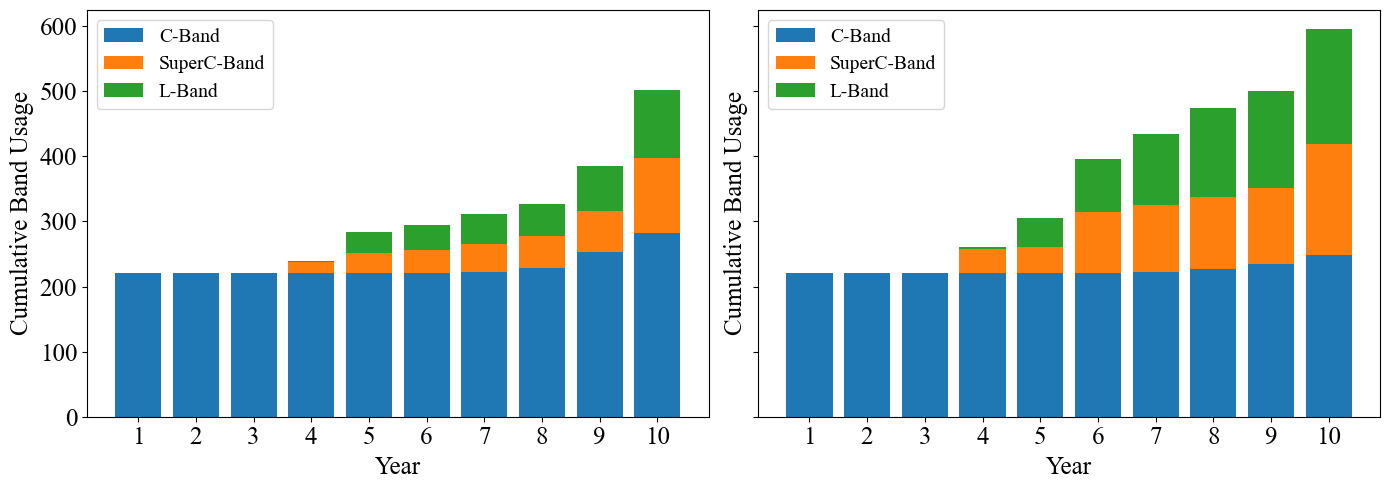

In [141]:
# Values per year
fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey = True)

axs[0].bar(year, deg_c_annual_noBypass, bottom = 0, label = 'C-Band')
axs[0].bar(year, deg_superc_annual_noBypass, bottom = deg_c_annual_noBypass, label = 'SuperC-Band')
axs[0].bar(year, deg_l_annual_noBypass, bottom = deg_c_annual_noBypass + deg_superc_annual_noBypass, label = 'L-Band')
axs[0].set_xlabel('Year')
axs[0].set_ylabel('Cumulative Band Usage', fontsize = 18)
axs[0].set_xlabel('Year', fontsize = 18)
axs[0].set_xticks(year)
axs[0].tick_params(axis='x', labelsize = 18)
axs[0].set_yticks(axs[0].get_yticks())
axs[0].set_yticklabels(axs[0].get_yticks().astype(int))
axs[0].tick_params(axis='y', labelsize = 18)

axs[1].bar(year, deg_c_annual_HL3Bypassed, bottom = 0, label = 'C-Band')
axs[1].bar(year, deg_superc_annual_HL3Bypassed, bottom = deg_c_annual_HL3Bypassed, label = 'SuperC-Band')
axs[1].bar(year, deg_l_annual_HL3Bypassed, bottom = deg_c_annual_HL3Bypassed + deg_superc_annual_HL3Bypassed, label = 'L-Band')
axs[1].set_xlabel('Year', fontsize = 18)
axs[1].set_xticks(year)
axs[1].tick_params(axis='x', labelsize = 18)
axs[1].set_yticks(axs[1].get_yticks())
axs[1].set_yticklabels(axs[1].get_yticks().astype(int))
axs[1].tick_params(axis='y', labelsize = 18)
axs[1].set_ylabel('Cumulative Band Usage', fontsize = 18)

# Unified legend
handles, labels = axs[0].get_legend_handles_labels()
axs[0].legend(handles, labels, loc='upper left', fontsize = 14)
axs[1].legend(handles, labels, loc='upper left', fontsize = 14)

plt.tight_layout()  # Leave space for title
# plt.savefig(save_directory / f"{network_noBypass.topology_name}_Band_Degree_BarPlot.png", format='png', dpi=600, bbox_inches='tight')
plt.show()

### *BVT and 100G License Usage*

In [142]:
Total_License_noBypass = 0
Total_License_HL3Bypassed = 0
Total_BVT_noBypass = 0
Total_BVT_HL3Bypassed = 0

for hierarchy_level in processing_level_list_noBypass:

    Total_License_noBypass += analyse_noBypass.bvt_data[f"HL{hierarchy_level}"]['HL_All_100G_lincense']
    Total_BVT_noBypass += analyse_noBypass.bvt_data[f"HL{hierarchy_level}"]['HL_BVTNum_All'].sum(axis = 1)

for hierarchy_level in processing_level_list_HL3Bypassed:

    Total_License_HL3Bypassed += analyse_HL3Bypassed.bvt_data[f"HL{hierarchy_level}"]['HL_All_100G_lincense']
    Total_BVT_HL3Bypassed += analyse_HL3Bypassed.bvt_data[f"HL{hierarchy_level}"]['HL_BVTNum_All'].sum(axis = 1)


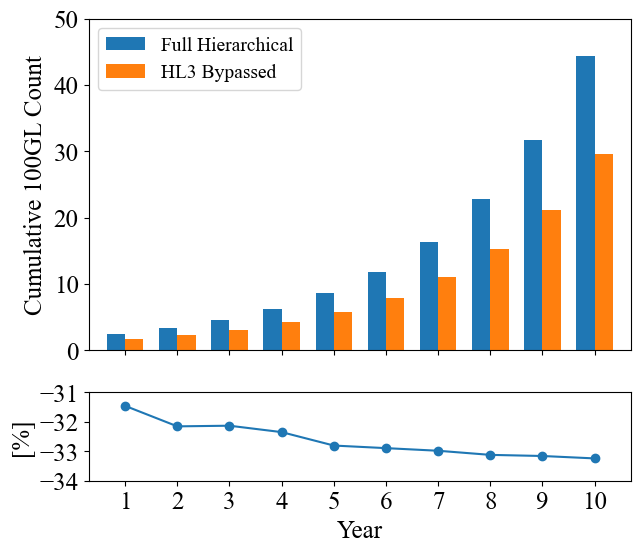

In [143]:
# Values per year
fig = plt.figure(figsize=(7, 6))
gs = gridspec.GridSpec(2, 1, height_ratios=[1.5, 0.4], wspace=0.25)

# Create all subplots
axs = [fig.add_subplot(gs[0]),
       fig.add_subplot(gs[1]), 
       ]

year = np.arange(1, total_simulation_time + 1)
width = 0.35

axs[0].bar(year - width/2, Total_License_noBypass, width = width, label = 'Full Hierarchical')
axs[0].bar(year + width/2, Total_License_HL3Bypassed, width = width, label = 'HL3 Bypassed')
axs[0].set_ylabel('Cumulative 100GL Count', fontsize = 18)
axs[0].legend(loc='upper left', fontsize = 14) 
axs[0].set_yticks(np.arange(0, 51000, 10000)) 
axs[0].set_yticklabels(np.arange(0, 51000, 10000) // 1000) 
axs[0].tick_params(axis='y', labelsize = 18)
axs[0].set_xticks(year)
axs[0].set_xticklabels([])
axs[0].tick_params(axis='x', labelsize = 18)


axs[1].plot(year, safe_percent_diff(Total_License_noBypass, Total_License_HL3Bypassed), '-o', color = 'C0')
axs[1].set_ylabel('[%]', fontsize = 18)
axs[1].tick_params(axis = 'x', labelsize = 18)
axs[1].set_xticks(year)
axs[1].set_xlabel('Year', fontsize = 18)
axs[1].tick_params(axis='y', labelsize = 18)
axs[1].set_yticks(np.arange(-34, -30, 1))

for ax in axs:
    ax.set_xlim(year.min() - 2 * width, year.max() + 2 * width)
    
plt.tight_layout()  # Leave space for title
# plt.savefig(save_directory / f"{network_noBypass.topology_name}_100GL_Usage.png", format='png', dpi=600, bbox_inches='tight')
plt.show()

### *Optical Cost*

In [144]:
df_cost_noBypass_C_IRU_0v5 = pd.read_csv(results_noBypass_dir / "MAN157_cost_analyse_NoBypass_C_IRU_0v5.csv")
df_cost_noBypass_C_IRU_0v01 = pd.read_csv(results_noBypass_dir / "MAN157_cost_analyse_NoBypass_C_IRU_0v01.csv")
df_cost_noBypass_C_IRU_5 = pd.read_csv(results_noBypass_dir / "MAN157_cost_analyse_NoBypass_C_IRU_5.csv")

df_cost_HL3Bypassed_C_IRU_0v5 = pd.read_csv(results_HL3Bypassed_dir / "MAN157_cost_analyse_HL3Bypassed_C_IRU_0v5.csv")
df_cost_HL3Bypassed_C_IRU_0v01 = pd.read_csv(results_HL3Bypassed_dir / "MAN157_cost_analyse_HL3Bypassed_C_IRU_0v01.csv")
df_cost_HL3Bypassed_C_IRU_5 = pd.read_csv(results_HL3Bypassed_dir / "MAN157_cost_analyse_HL3Bypassed_C_IRU_5.csv")

#### *Plot Spider Plot for Different Optical Elements*

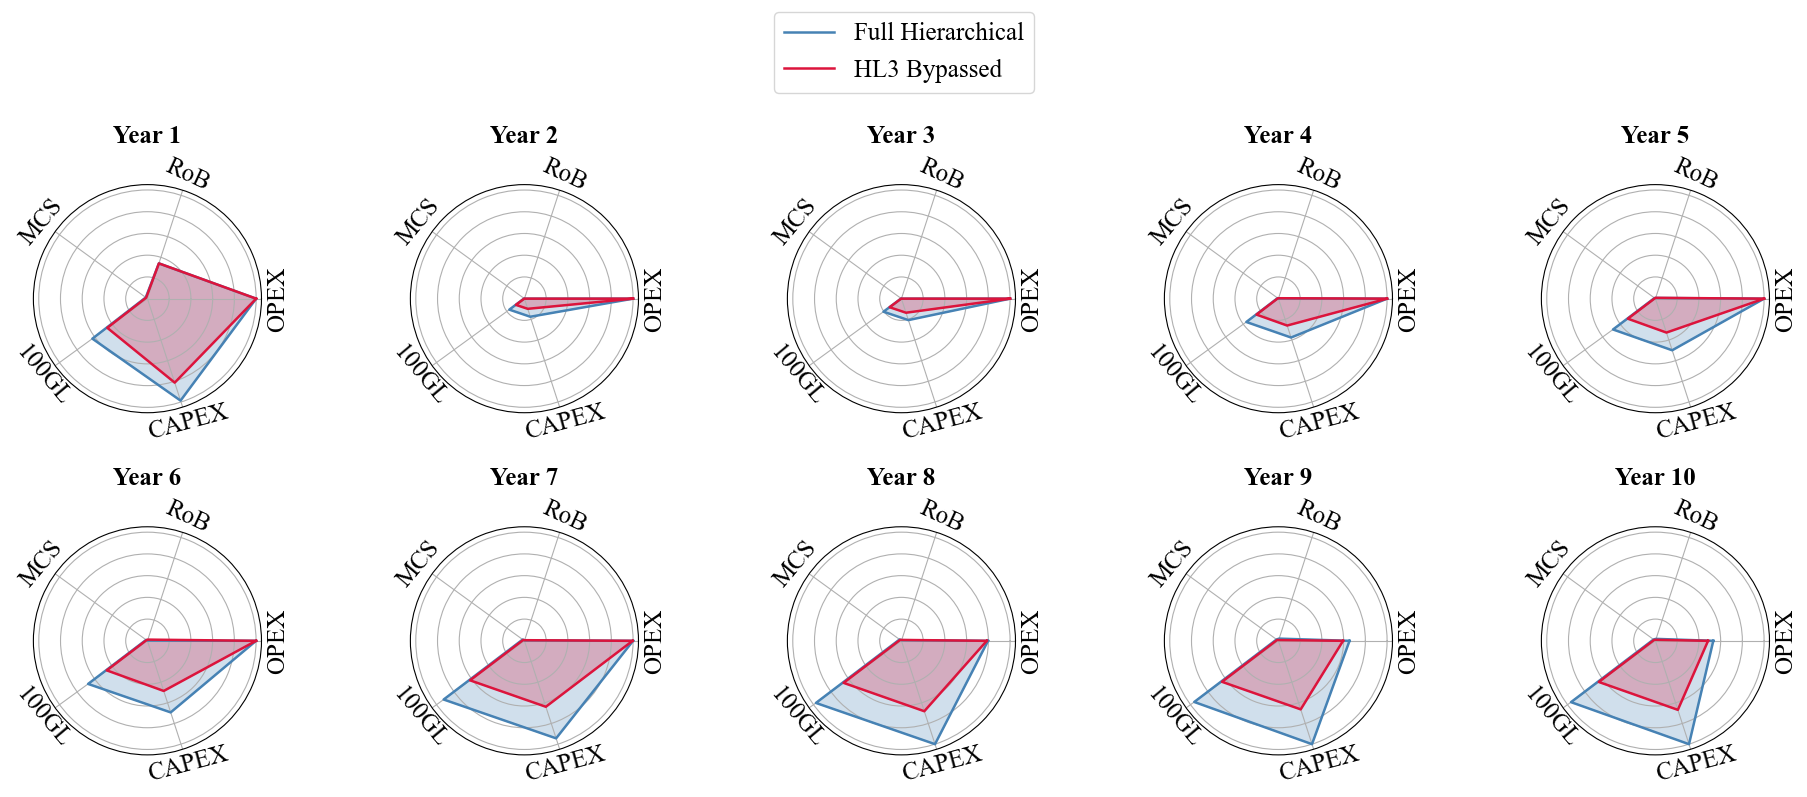

In [145]:
labels = ['OPEX', 'Capex_RoB', 'Capex_MCS', 'Capex_100GL', 'CAPEX']
n_vars = len(labels)

# Angles for radar
angles = np.linspace(0, 2 * np.pi, n_vars, endpoint=False).tolist()
angles += angles[:1]

fig, axs = plt.subplots(2, 5, figsize=(20, 8), subplot_kw={'polar': True})

# Plot each year
for i in range(10):
    row = i // 5
    col = i % 5
    ax = axs[row][col]

    # Get values
    val_nb = df_cost_noBypass_C_IRU_0v5.loc[i, labels].values.tolist()
    val_bp = df_cost_HL3Bypassed_C_IRU_0v5.loc[i, labels].values.tolist()

    # Optional normalization (per year)
    all_vals = val_nb + val_bp
    max_val = max(all_vals)
    val_nb = [v / max_val for v in val_nb]
    val_bp = [v / max_val for v in val_bp]

    # Close the loop
    val_nb += val_nb[:1]
    val_bp += val_bp[:1]

    # Plot
    ax.plot(angles, val_nb, label="Full Hierarchical", color="steelblue", linewidth=1.8)
    ax.fill(angles, val_nb, color="steelblue", alpha=0.25)
    ax.plot(angles, val_bp, label="HL3 Bypassed", color="crimson", linewidth=1.8)
    ax.fill(angles, val_bp, color="crimson", alpha=0.25)

    # Labels
    ax.set_title(f"Year {i+1}", fontsize=18, pad=30, fontweight='bold')
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_rlabel_position(20)
    
    text_angle = [90, -25, 50, -50, 15]
    radius = ax.get_rmax() + 0.15 # slightly outside the circle
    counter = 0
    for angle, label in zip(angles[:-1], ['OPEX', 'RoB', 'MCS', '100GL', 'CAPEX']):
        ax.text(angle, radius, label, fontsize = 18,
				rotation=text_angle[counter],
				rotation_mode='anchor',
				ha='center', va='center')
        counter += 1
    
# Unified legend
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', fontsize = 18)

# Layout
plt.tight_layout(rect=[0, 0, 0.95, 0.85])
plt.subplots_adjust(hspace=0.5)  # Increase vertical space between rows
# plt.savefig(save_directory / f"{network_noBypass.topology_name}_Cost_Structure_Comparison_{channel_spacing}G.png", format='png', dpi=600, bbox_inches='tight')
plt.show()


### *Router Deployement*

In [146]:
routers_tracker_array_noBypass = np.load(results_noBypass_dir / "MAN157_routers_tracker_array_noBypass.npz")['routers_tracker_array']
routers_tracker_array_HL3Bypassed = np.load(results_HL3Bypassed_dir / "MAN157_routers_tracker_array_HL3Bypassed.npz")['routers_tracker_array']

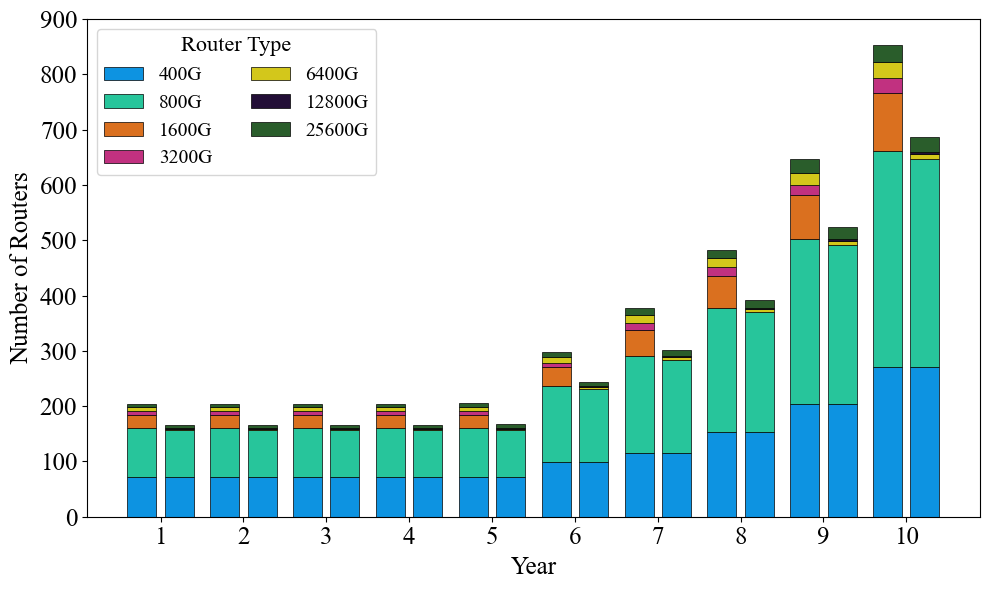

In [147]:
fig, ax = plt.subplots(figsize=(10, 6))

bottom_noBypass = np.zeros_like(year)
bottom_HL3Bypassed = np.zeros_like(year)
labels = ['400G','800G','1600G','3200G', '6400G', '12800G','25600G']
width = 0.35
colors = [
    "#0D93E1",
    "#27C59B", 
    "#DA701F",
    "#C13180", 
    "#D3C71B", 
    "#220E36", 
    "#2A5D2B" 
]

for i in range(len(labels)):
    if routers_tracker_array_noBypass[i].any() == 0:
        continue
    
    else:
        ax.bar(year - (width / 2 + 0.05), 
               routers_tracker_array_noBypass[i], 
               bottom=bottom_noBypass, 
               label=labels[i], 
               width = width,
               edgecolor='black',
               linewidth=0.5,
               color = colors[i])
        bottom_noBypass += routers_tracker_array_noBypass[i]
        
for i in range(len(labels)):
    if routers_tracker_array_HL3Bypassed[i].any() == 0:
        continue
    
    else:
        ax.bar(year + width / 2 + 0.05, 
               routers_tracker_array_HL3Bypassed[i], 
               bottom=bottom_HL3Bypassed, 
               width = width, 
               label=labels[i],
               edgecolor='black',  # makes hatch visible
               linewidth=0.5,
               color = colors[i])
        bottom_HL3Bypassed += routers_tracker_array_HL3Bypassed[i]

ax.set_ylabel('Number of Routers', fontsize=18)
ax.set_xlabel('Year', fontsize=18)
ax.set_xticks(year)
ax.tick_params(axis='y', labelsize = 18)
ax.tick_params(axis='x', labelsize = 18)
ax.set_yticks(np.arange(0, 901, 100))

# Build unique legend items (handle:label)
handles, labels_uniq = ax.get_legend_handles_labels()
by_label = dict(zip(labels_uniq, handles))

by_label = {
    '400G': by_label['400G'], 
    '800G': by_label['800G'], 
    '1600G': by_label['1600G'], 
    '3200G': by_label['3200G'], 
    '6400G': by_label['6400G'], 
    '12800G': by_label['12800G'], 
    '25600G': by_label['25600G']
}
# Apply filtered legend
ax.legend(by_label.values(), by_label.keys(), 
          loc='upper left', fontsize=14, 
          title='Router Type', title_fontsize=16, 
          ncol = 2)

plt.tight_layout()
# plt.savefig(save_directory / f"num_routers_{channel_spacing}.png", format='png', dpi=600, bbox_inches='tight')
plt.show()


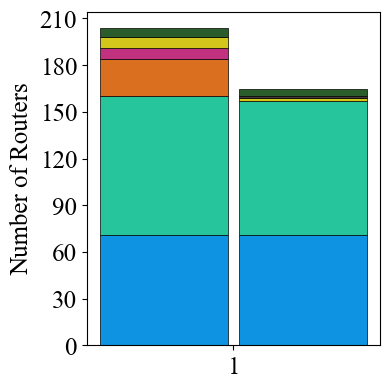

In [148]:
fig, ax = plt.subplots(figsize=(4, 4))

year_part = np.array([1])
bottom_noBypass = np.zeros_like(year_part)
bottom_HL3Bypassed = np.zeros_like(year_part)
labels = ['400G','800G','1600G','3200G', '6400', '12800G','25600G']
width = 0.25
colors = [
    "#0D93E1",
    "#27C59B", 
    "#DA701F",
    "#C13180",
    "#D3C71B",
    "#433838",
    "#2A5D2B" 
]
for i in range(len(labels)):
    
    if routers_tracker_array_noBypass[i].any() == 0:
        continue
    
    else:
        ax.bar(year_part - (width / 2 + 0.01), 
               routers_tracker_array_noBypass[i][:1], 
               bottom=bottom_noBypass, 
               label=labels[i], 
               width = width,
               edgecolor='black',
               linewidth=0.5,
               color = colors[i])
        bottom_noBypass += routers_tracker_array_noBypass[i][:1]

for i in range(len(labels)):

    if routers_tracker_array_HL3Bypassed[i].any() == 0:
        continue
    
    else:
        ax.bar(year_part + width / 2 + 0.01, 
               routers_tracker_array_HL3Bypassed[i][:1], 
               bottom=bottom_HL3Bypassed, 
               width = width, 
               label = labels[i],
               edgecolor='black', 
               linewidth=0.5,
               color = colors[i])
        bottom_HL3Bypassed += routers_tracker_array_HL3Bypassed[i][:1]
        
ax.set_ylabel('Number of Routers', fontsize=18)
ax.set_xticks(year_part)
ax.tick_params(axis='y', labelsize = 18)
ax.tick_params(axis='x', labelsize = 18)
ax.set_yticks(np.arange(0, 211, 30))


plt.tight_layout()
# plt.savefig(save_directory / f"num_routers_1Years_{channel_spacing}.png", format='png', dpi=600, bbox_inches='tight')
plt.show()


### *IP (Electrical) Cost and Power Consumption*

In [149]:
IP_total_cost_noBypass = np.load(results_noBypass_dir / "MAN157_IP_Cost_Power_noBypass.npz")['IP_Cost_Cum']
IP_total_cost_HL3Bypassed = np.load(results_HL3Bypassed_dir / "MAN157_IP_Cost_Power_HL3Bypassed.npz")['IP_Cost_Cum']

IP_total_power_noBypass = np.load(results_noBypass_dir / "MAN157_IP_Cost_Power_noBypass.npz")['IP_Power_Cum']
IP_total_power_HL3Bypassed = np.load(results_HL3Bypassed_dir / "MAN157_IP_Cost_Power_HL3Bypassed.npz")['IP_Power_Cum']

In [150]:
IP_total_cost_HL3Bypassed

array([1003.2, 1003.2, 1003.2, 1003.2, 1208. , 1579.2, 2156.8, 2652.8,
       3731.2, 4811.2])

### *Optical + Electrical Cost (TCO)*

In [151]:
TCO_noBypass = df_cost_noBypass_C_IRU_0v5['OPEX'] + df_cost_noBypass_C_IRU_0v5['CAPEX']
TCO_HL3Bypassed = df_cost_HL3Bypassed_C_IRU_0v5['OPEX'] + df_cost_HL3Bypassed_C_IRU_0v5['CAPEX']

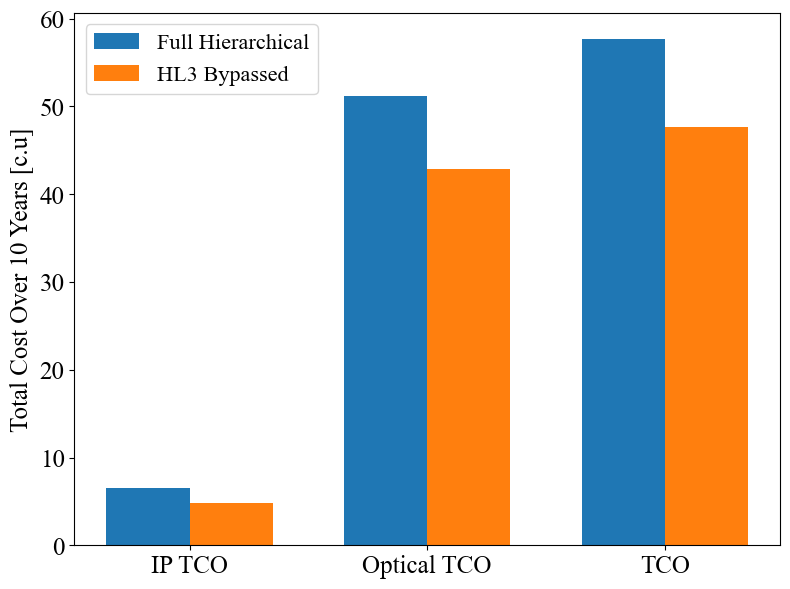

In [152]:
labels = ["IP TCO", 'Optical TCO', 'TCO']
bypass_totals = np.array([IP_total_cost_HL3Bypassed[-1], TCO_HL3Bypassed.sum(), IP_total_cost_HL3Bypassed[-1] + TCO_HL3Bypassed.sum()])
nobypass_totals = np.array([IP_total_cost_noBypass[-1], TCO_noBypass.sum(), IP_total_cost_noBypass[-1] + TCO_noBypass.sum()])

x = np.arange(len(labels))
width = 0.35

fig, axs = plt.subplots(figsize = (8, 6))

axs.bar(x - width/2, nobypass_totals, width, label='Full Hierarchical')
axs.bar(x + width/2, bypass_totals, width, label='HL3 Bypassed')
axs.set_xticks(x, labels)
axs.set_ylabel(r"Total Cost Over 10 Years [c.u]", fontsize = 18)
axs.tick_params(axis='y', labelsize = 18)
axs.tick_params(axis='x', labelsize = 18)
axs.set_yticks(np.arange(0, 60001, 10000))
axs.set_yticklabels(np.arange(0, 60001, 10000) // 1000)
axs.legend(loc = 'upper left', fontsize = 16)

plt.tight_layout()
# plt.savefig(save_directory / f"{network_noBypass.topology_name}_TCO.png", format='png', dpi=600, bbox_inches='tight')
plt.show()

In [153]:
safe_percent_diff(nobypass_totals, bypass_totals)

array([-26.35317169, -16.33733449, -17.47080825])

In [154]:
print(nobypass_totals)
print(bypass_totals)

[ 6532.8        51193.68965875 57726.48965875]
[ 4811.2        42830.00533932 47641.20533932]


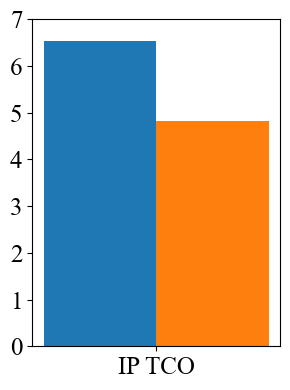

In [155]:
labels = ["IP TCO"]
bypass_totals = [IP_total_cost_HL3Bypassed[-1]]
nobypass_totals = [IP_total_cost_noBypass[-1]]

x = np.arange(len(labels))
width = 0.35

fig, axs = plt.subplots(figsize = (3, 4))

axs.bar(x - width/2, nobypass_totals, width, label='Full Hierarchical')
axs.bar(x + width/2, bypass_totals, width, label='HL3 Bypassed')
axs.set_xticks(x, labels)
axs.tick_params(axis='y', labelsize = 18)
axs.tick_params(axis='x', labelsize = 18)
axs.set_yticks(np.arange(0, 7001, 1000))
axs.set_yticklabels(np.arange(0, 7001, 1000) // 1000)

plt.tight_layout()
plt.show()

### *Energy Consumption*

In [156]:
energy_consumption_annual_noBypass = np.load(results_noBypass_dir / "MAN157_energy_optical_electrical_noBypass.npz")['optical_energy_annual']
energy_consumption_annual_HL3Bypassed = np.load(results_HL3Bypassed_dir / "MAN157_energy_optical_electrical_HL3Bypassed.npz")['optical_energy_annual']

total_served_traffic_noBypass = np.load(results_noBypass_dir / "MAN157_energy_optical_electrical_noBypass.npz")['total_served_traffic']
total_served_traffic_HL3Bypassed = np.load(results_HL3Bypassed_dir / "MAN157_energy_optical_electrical_HL3Bypassed.npz")['total_served_traffic']

IP_energy_consumption_annual_noBypass = np.load(results_noBypass_dir / "MAN157_energy_optical_electrical_noBypass.npz")['IP_energy_annual']
IP_energy_consumption_annual_HL3Bypassed = np.load(results_HL3Bypassed_dir / "MAN157_energy_optical_electrical_HL3Bypassed.npz")['IP_energy_annual']

In [157]:
safe_percent_diff(energy_consumption_annual_noBypass, energy_consumption_annual_HL3Bypassed)

array([-18.51217089, -66.66666667, -41.86046512, -24.98307001,
       -35.35356208, -21.53555813, -32.29185386, -31.35931214,
       -34.05392909, -33.19220544])

In [158]:
safe_percent_diff(IP_energy_consumption_annual_noBypass, IP_energy_consumption_annual_HL3Bypassed)

array([-25.52646036,   0.        ,   0.        ,   0.        ,
       -27.63157895, -17.74403471, -36.89991863, -18.86862672,
       -26.50999341, -28.22983583])

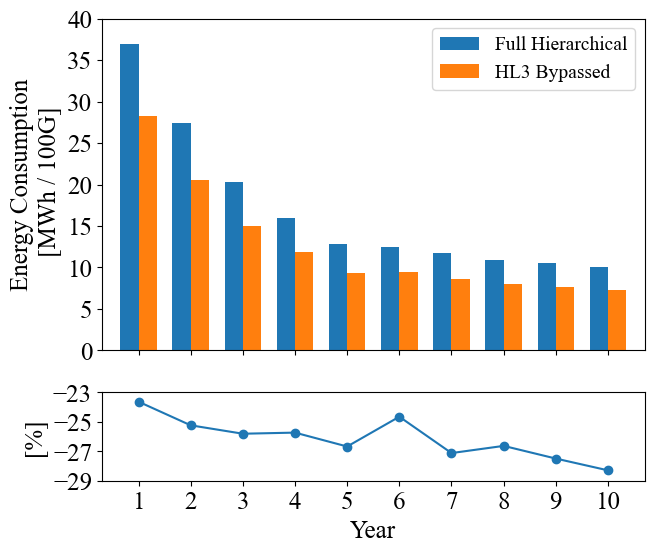

In [159]:
# Values per year
fig = plt.figure(figsize=(7, 6))
gs = gridspec.GridSpec(2, 1, height_ratios=[1.5, 0.4], wspace=0.25)

# Create all subplots
axs = [fig.add_subplot(gs[0]),
       fig.add_subplot(gs[1]), 
       ]

norm_noBypass = (IP_energy_consumption_annual_noBypass + energy_consumption_annual_noBypass).cumsum() / (total_served_traffic_noBypass * 0.01)
norm_bypass = (IP_energy_consumption_annual_HL3Bypassed + energy_consumption_annual_HL3Bypassed).cumsum() / (total_served_traffic_HL3Bypassed * 0.01)

year = np.arange(1, total_simulation_time + 1)
bar_width = 0.35

axs[0].bar(year - bar_width / 2, 
           norm_noBypass, 
           width=bar_width, 
           label='Full Hierarchical')

axs[0].bar(year + bar_width / 2, 
           norm_bypass, 
           width=bar_width, 
           label='HL3 Bypassed')

axs[0].set_ylabel('Energy Consumption\n [MWh / 100G]', fontsize = 18)
axs[0].legend(loc='upper right', fontsize = 14) 
axs[0].set_yticks(np.arange(0, max(norm_noBypass.max(), norm_bypass.max())+5, 5))
axs[0].tick_params(axis='y', labelsize = 18)
axs[0].set_xticks(year)
axs[0].set_xticklabels([])
axs[0].tick_params(axis='x', labelsize = 18)


axs[1].plot(year, safe_percent_diff(norm_noBypass, norm_bypass), '-o', color = 'C0')
axs[1].set_ylabel('[%]', fontsize = 18)
axs[1].tick_params(axis = 'x', labelsize = 18)
axs[1].set_xticks(year)
axs[1].set_xlabel('Year', fontsize = 18)
axs[1].tick_params(axis='y', labelsize = 18)
axs[1].set_yticks(np.arange(-29, -22, 2))

for ax in axs:
    ax.set_xlim(year.min() - 2 * width, year.max() + 2 * width)
    
plt.tight_layout()
# plt.savefig(save_directory /
#             f"{network_noBypass.topology_name}_Total_Energy_consumption_normalized.png",
#             format='png', dpi=600, bbox_inches='tight')
plt.show()

In [160]:
safe_percent_diff(norm_noBypass, norm_bypass)

array([-23.63727589, -25.23983576, -25.8110058 , -25.73566699,
       -26.67894552, -24.65625405, -27.1238231 , -26.63631565,
       -27.49645243, -28.296039  ])

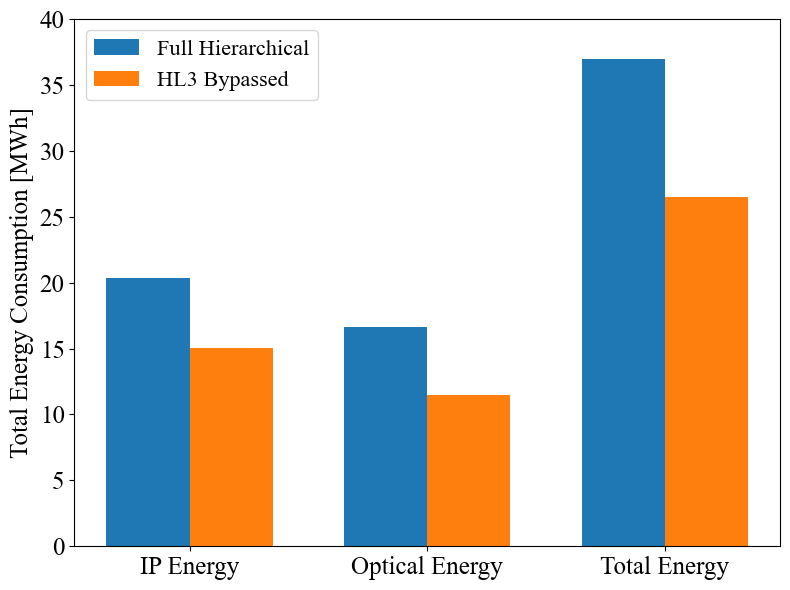

In [161]:
labels = ["IP Energy", "Optical Energy", "Total Energy"]

bypass_totals = [
    IP_energy_consumption_annual_HL3Bypassed.cumsum()[-1],
    energy_consumption_annual_HL3Bypassed.cumsum()[-1],
    IP_energy_consumption_annual_HL3Bypassed.cumsum()[-1] + energy_consumption_annual_HL3Bypassed.cumsum()[-1]
]

nobypass_totals = [
    IP_energy_consumption_annual_noBypass.cumsum()[-1],
    energy_consumption_annual_noBypass.cumsum()[-1],
    IP_energy_consumption_annual_noBypass.cumsum()[-1] + energy_consumption_annual_noBypass.cumsum()[-1]
]

x = np.arange(len(labels))
width = 0.35

fig, axs = plt.subplots(figsize=(8, 6))

axs.bar(x - width/2, nobypass_totals, width,
        label='Full Hierarchical')
axs.bar(x + width/2, bypass_totals, width,
        label='HL3 Bypassed')

axs.set_xticks(x)
axs.set_xticklabels(labels, fontsize=18)
axs.set_ylabel(r"Total Energy Consumption [MWh]", fontsize=18)
axs.tick_params(axis='y', labelsize=18)
axs.legend(loc='upper left', fontsize=16)
axs.set_yticks(np.arange(0, 40001, 5000))
axs.set_yticklabels(np.arange(0, 40001, 5000) // 1000)


rel_diff = [
    safe_percent_diff(nobypass_totals[0], bypass_totals[0]),
    safe_percent_diff(nobypass_totals[1], bypass_totals[1]),
    safe_percent_diff(nobypass_totals[2], bypass_totals[2])
]

plt.tight_layout()
# plt.savefig(save_directory / f"{network_noBypass.topology_name}_Total_Energy_Consumption.png",
#             format='png', dpi=600, bbox_inches='tight')
plt.show()


In [162]:
rel_diff

[array(-26.04651163), array(-31.04490816), array(-28.296039)]

#### *Calculate Sub-Networks*

In [163]:
sub_graph_HL, subnetMatrix_HL = network_noBypass.compute_hierarchy_subgraph(4, 4)
HL_subnet_links = np.array(list(sub_graph_HL.edges(data = 'weight')))
mask = np.any(np.all(network_noBypass.all_links[:, None] == HL_subnet_links, axis = 2), axis=1)
HL_links_indices_HL4 = np.where(mask)[0]

sub_graph_HL, subnetMatrix_HL = network_noBypass.compute_hierarchy_subgraph(3, 4)
HL_subnet_links = np.array(list(sub_graph_HL.edges(data = 'weight')))
mask = np.any(np.all(network_noBypass.all_links[:, None] == HL_subnet_links, axis = 2), axis=1)
HL_links_indices_HL3 = np.where(mask)[0]

sub_graph_HL, subnetMatrix_HL = network_noBypass.compute_hierarchy_subgraph(2, 4)
HL_subnet_links = np.array(list(sub_graph_HL.edges(data = 'weight')))
mask = np.any(np.all(network_noBypass.all_links[:, None] == HL_subnet_links, axis = 2), axis=1)
HL_links_indices_HL2 = np.where(mask)[0]

### *Traffic Flow on Links*

In [164]:
traffic_flow_array_noBypass = analyse_noBypass.link_data['HL2']['traffic_flow_links_array'].cumsum(axis = 0)
traffic_flow_array_HL3Bypassed = analyse_HL3Bypassed.link_data['HL2']['traffic_flow_links_array'].cumsum(axis = 0)

traffic_flow_array_noBypass_sorted = sort_by_weight(traffic_flow_array_noBypass, processing_level_list_noBypass)
traffic_flow_array_HL3Bypassed_sorted = sort_by_weight(traffic_flow_array_HL3Bypassed, processing_level_list_noBypass)

# Average over years
avg_traffic_nb = traffic_flow_array_noBypass_sorted.mean(axis=0)
avg_traffic_bp = traffic_flow_array_HL3Bypassed_sorted.mean(axis=0)

In [165]:
# print(avg_traffic_nb[HL_links_indices_HL4].mean())
# print(avg_traffic_bp[HL_links_indices_HL4].mean())
# print(safe_percent_diff(avg_traffic_nb[HL_links_indices_HL4].mean(), avg_traffic_bp[HL_links_indices_HL4].mean()))

In [166]:
# print(avg_traffic_nb[HL_links_indices_HL3].mean())
# print(avg_traffic_bp[HL_links_indices_HL3].mean())

# print(safe_percent_diff(
#     avg_traffic_nb[HL_links_indices_HL3].mean(),
#     avg_traffic_bp[HL_links_indices_HL3].mean()
# ))

# print(safe_percent_diff(
#     avg_traffic_nb[HL_links_indices_HL2].mean(),
#     avg_traffic_bp[HL_links_indices_HL2].mean()
# ))

# print(avg_traffic_nb[HL_links_indices_HL2].mean())
# print(avg_traffic_bp[HL_links_indices_HL2].mean())

#### *Define a Function to Calculate the Statistics*

In [167]:
def format_stats(data):
    return (
        f"Mean: {np.mean(data):.3f}\n"
        f"Std: {np.std(data):.3f}\n"
        f"Min: {np.min(data):.3f}\n"
        f"Max: {np.max(data):.3f}"
    )

In [168]:
# nbp_stats = format_stats(avg_traffic_nb)
# bp_stats = format_stats(avg_traffic_bp)

# print(nbp_stats)
# print('----------')
# print(bp_stats)

#### *Plot Traffic Distribution*

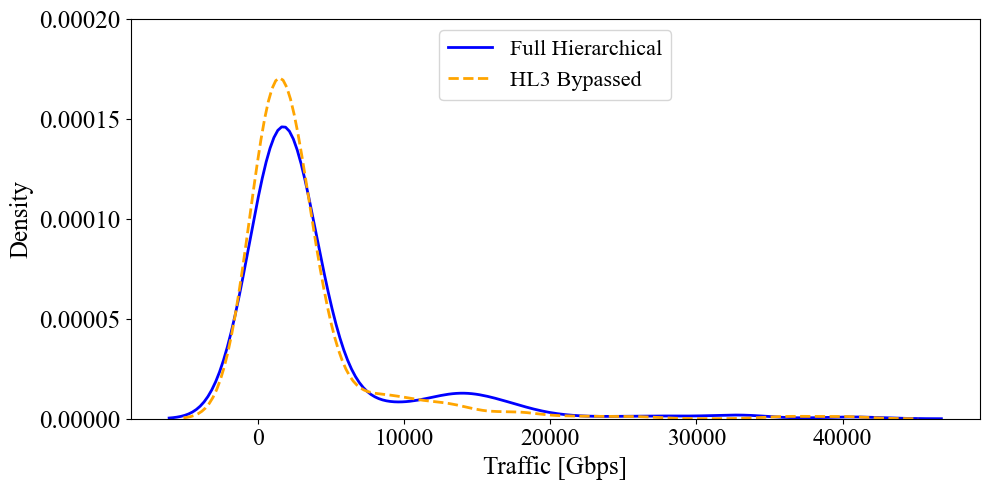

In [169]:
plt.figure(figsize=(10, 5))
sns.kdeplot(avg_traffic_nb, color="blue", label="Full Hierarchical", linewidth=2)
sns.kdeplot(avg_traffic_bp, color="orange", label="HL3 Bypassed", linewidth=2, linestyle='--')   
plt.xlabel("Traffic [Gbps]", fontsize = 18)
plt.ylabel("Density", fontsize = 18)
plt.legend(loc = 'upper center', 
           fontsize = 16)
plt.tick_params(axis='x', labelsize = 17)
plt.tick_params(axis='y', labelsize = 18)
plt.yticks(plt.gca().get_yticks())

plt.tight_layout()
# plt.savefig(save_directory / f"{network_noBypass.topology_name}_Traffic_Flow_Dist_total_{channel_spacing}G.png", format='png', dpi=600, bbox_inches='tight')
plt.show()


#### *Specify Hotspot Links*

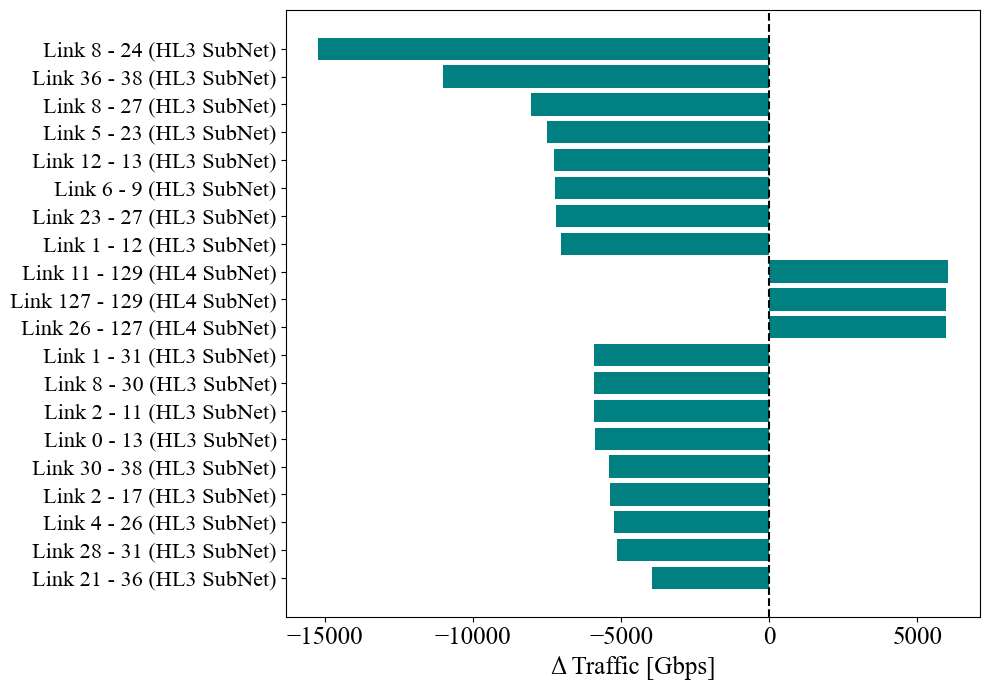

In [170]:
delta = traffic_flow_array_HL3Bypassed.mean(axis = 0) - traffic_flow_array_noBypass.mean(axis = 0)
number_of_top = 20
top_change = np.argsort(np.abs(delta))[-number_of_top:]
top_change_info = network_noBypass.all_links[top_change, :]
top_links_subnet = []

for link in top_change_info:
    link_idX = np.where((network_noBypass.all_links[:, 0] == link[0]) & (network_noBypass.all_links[:, 1] == link[1]))[0]
    if link_idX in HL_links_indices_HL4:
        top_links_subnet.append('HL4 SubNet')
    elif link_idX in HL_links_indices_HL3:
        top_links_subnet.append('HL3 SubNet')
    elif link_idX in HL_links_indices_HL2:
        top_links_subnet.append('HL2 SubNet')

plt.figure(figsize=(10, 7))
plt.barh(range(len(top_change)), delta[top_change], color='teal')
plt.yticks(range(len(top_change)), [f"Link {int(link[0][0])} - {int(link[0][1])} ({link[1]})" for link in zip(top_change_info, top_links_subnet)])
plt.axvline(0, color='black', linestyle='--')
plt.xlabel(r"Δ Traffic [Gbps]", fontsize = 18)
plt.tick_params(axis='y', labelsize = 16)
plt.tick_params(axis='x', labelsize = 18)

plt.tight_layout()
# plt.savefig(save_directory / f"{network_noBypass.topology_name}_Top_Links_Traffic_Flow_Change_{channel_spacing}G.png", format='png', dpi=600, bbox_inches='tight')
plt.show()


### *Latency Analysis*

In [171]:
latency_noBypass = np.load(results_noBypass_dir / "MAN157_Average_Latency.npz")['latency']
latency_HL3Bypassed = np.load(results_HL3Bypassed_dir / "MAN157_Average_Latency.npz")['latency']

nbp_stats = format_stats(latency_noBypass)
bp_stats = format_stats(latency_HL3Bypassed)

print(nbp_stats)
print('----------')
print(bp_stats)

Mean: 622.846
Std: 284.480
Min: 25.621
Max: 1537.850
----------
Mean: 514.837
Std: 244.931
Min: 17.019
Max: 1201.323


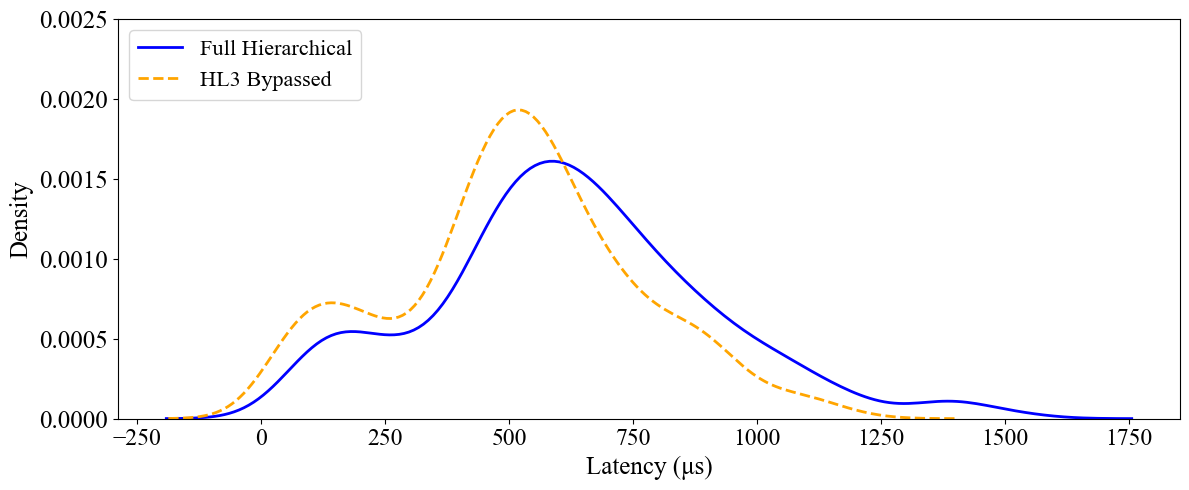

In [172]:
plt.figure(figsize=(12, 5))
sns.kdeplot(latency_noBypass, color="blue", label="Full Hierarchical", linewidth=2)
sns.kdeplot(latency_HL3Bypassed, color="orange", label="HL3 Bypassed", linewidth=2, linestyle='--')   
plt.xlabel("Latency (μs)", fontsize = 18)
plt.ylabel("Density", fontsize = 18)
plt.legend(loc = 'upper left', 
           fontsize = 16)
plt.tick_params(axis='x', labelsize = 17)
plt.tick_params(axis='y', labelsize = 18)
plt.yticks(plt.gca().get_yticks())
# plt.xlim([400, 3000])

plt.tight_layout()
# plt.savefig(save_directory / f"{network_noBypass.topology_name}_Latency_Distribution.png", format='png', dpi=600, bbox_inches='tight')
plt.show()


### *QoT Analysis*

In [173]:
GSNR_all_paths_HL4_noBypass = analyse_noBypass.GSNR_data['HL4']['GSNR_all_paths']
GSNR_all_paths_HL3_noBypass = analyse_noBypass.GSNR_data['HL3']['GSNR_all_paths']
GSNR_all_paths_HL2_noBypass = analyse_noBypass.GSNR_data['HL2']['GSNR_all_paths']

GSNR_all_paths_HL4_noBypass_flat = np.concatenate(GSNR_all_paths_HL4_noBypass)
GSNR_all_paths_HL3_noBypass_flat = np.concatenate(GSNR_all_paths_HL3_noBypass)
GSNR_all_paths_HL2_noBypass_flat = np.concatenate(GSNR_all_paths_HL2_noBypass)

In [174]:
GSNR_all_paths_HL4_HL3Bypassed = analyse_HL3Bypassed.GSNR_data['HL4']['GSNR_all_paths']
GSNR_all_paths_HL2_HL3Bypassed = analyse_HL3Bypassed.GSNR_data['HL2']['GSNR_all_paths']

GSNR_all_paths_HL4_HL3Bypassed_flat = np.concatenate(GSNR_all_paths_HL4_HL3Bypassed)
GSNR_all_paths_HL2_HL3Bypassed_flat = np.concatenate(GSNR_all_paths_HL2_HL3Bypassed)

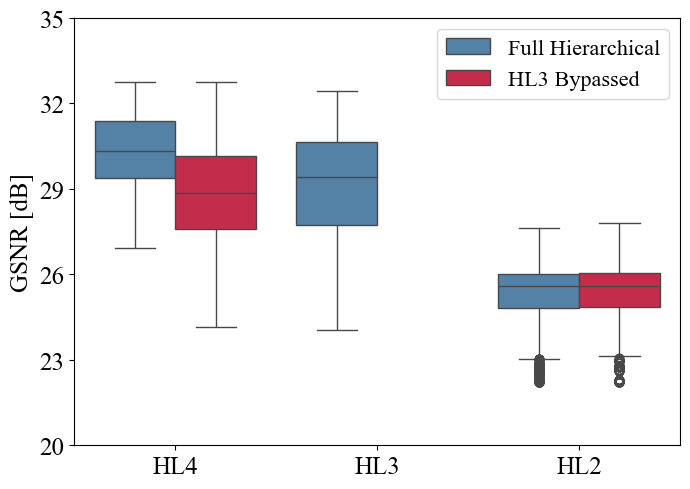

In [175]:

# --- Build DataFrame for noBypass ---
df_noBypass = pd.DataFrame({
    'Metric': np.concatenate([GSNR_all_paths_HL4_noBypass_flat, GSNR_all_paths_HL3_noBypass_flat, GSNR_all_paths_HL2_noBypass_flat]),
    'Site': ['HL4'] * len(GSNR_all_paths_HL4_noBypass_flat) + ['HL3'] * len(GSNR_all_paths_HL3_noBypass_flat) + ['HL2'] * len(GSNR_all_paths_HL2_noBypass_flat),
    'Type': ['Full Hierarchical'] * (len(GSNR_all_paths_HL4_noBypass_flat) + len(GSNR_all_paths_HL3_noBypass_flat) + + len(GSNR_all_paths_HL2_noBypass_flat))
})

# --- Build DataFrame for Bypassed ---
df_bypassed = pd.DataFrame({
    'Metric': np.concatenate([GSNR_all_paths_HL4_HL3Bypassed_flat, GSNR_all_paths_HL2_HL3Bypassed_flat]),
    'Site': ['HL4'] * len(GSNR_all_paths_HL4_HL3Bypassed_flat) + ['HL2'] * len(GSNR_all_paths_HL2_HL3Bypassed_flat),
    'Type': ['HL3 Bypassed'] * (len(GSNR_all_paths_HL4_HL3Bypassed_flat) + len(GSNR_all_paths_HL2_HL3Bypassed_flat))
})

# --- Combine both ---
df_all = pd.concat([df_noBypass, df_bypassed], ignore_index=True)

# --- Plot ---
plt.figure(figsize=(7, 5))
sns.boxplot(
    x='Site',
    y='Metric',
    hue='Type', 
    data=df_all,
    palette={'Full Hierarchical': 'steelblue', 'HL3 Bypassed': 'crimson'}
)

plt.legend(fontsize = 16)   # legend showing noBypass vs Bypassed
plt.ylabel("GSNR [dB]", fontsize = 18)
plt.tick_params(axis='x', labelsize = 18)
plt.tick_params(axis='y', labelsize = 18)
plt.yticks(np.arange(20, 37, 3))
plt.xlabel('', fontsize = 18)
plt.tight_layout()
# plt.savefig(save_directory / f"all_paths_GSNR_comparison.png", format='png', dpi=600, bbox_inches='tight')
plt.show()


In [176]:
df_noBypass[df_noBypass['Site'] == 'HL4']['Metric'].mean()

np.float64(30.3797308140577)

In [177]:
df_noBypass[df_noBypass['Site'] == 'HL3']['Metric'].mean()

np.float64(29.160964320462835)

In [178]:
df_noBypass[df_noBypass['Site'] == 'HL2']['Metric'].mean()

np.float64(25.36323001546169)

In [179]:
df_bypassed[df_bypassed['Site'] == 'HL4']['Metric'].mean()

np.float64(28.783134091342813)

In [180]:
df_bypassed[df_bypassed['Site'] == 'HL2']['Metric'].mean()

np.float64(25.44872533124341)

In [109]:
links_GSNR_HL4_noBypass = np.load(results_noBypass_dir / "MAN157_process_GSNR_HL4.npz")['GSNR_opt_link']
links_GSNR_HL3_noBypass = np.load(results_noBypass_dir / "MAN157_process_GSNR_HL3.npz")['GSNR_opt_link']
links_GSNR_HL2_noBypass = np.load(results_noBypass_dir / "MAN157_process_GSNR_HL2.npz")['GSNR_opt_link']

links_GSNR_HL4_HL3Bypassed = np.load(results_HL3Bypassed_dir / "MAN157_process_GSNR_HL4.npz")['GSNR_opt_link']
links_GSNR_HL2_HL3Bypassed = np.load(results_HL3Bypassed_dir / "MAN157_process_GSNR_HL2.npz")['GSNR_opt_link']

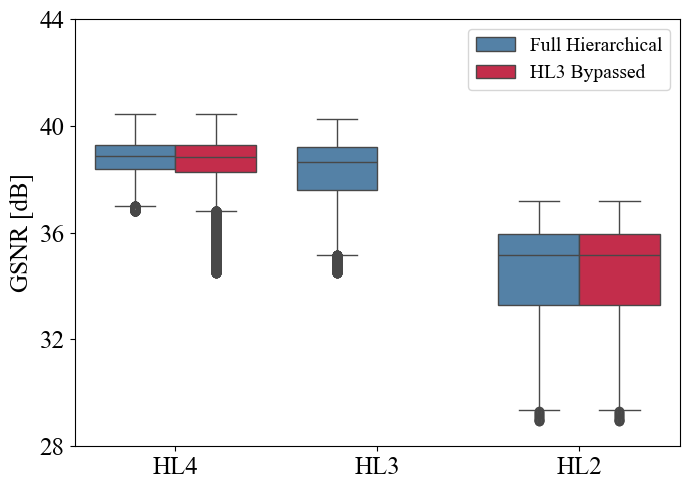

In [110]:

# --- Build DataFrame for noBypass ---
df_noBypass = pd.DataFrame({
    'Metric': np.concatenate([links_GSNR_HL4_noBypass.flatten(), links_GSNR_HL3_noBypass.flatten(), links_GSNR_HL2_noBypass.flatten()]),
    'Site': ['HL4'] * len(links_GSNR_HL4_noBypass.flatten()) + ['HL3'] * len(links_GSNR_HL3_noBypass.flatten()) + ['HL2'] * len(links_GSNR_HL2_noBypass.flatten()),
    'Type': ['Full Hierarchical'] * (len(links_GSNR_HL4_noBypass.flatten()) + len(links_GSNR_HL3_noBypass.flatten()) + + len(links_GSNR_HL2_noBypass.flatten()))
})

# --- Build DataFrame for Bypassed ---
df_bypassed = pd.DataFrame({
    'Metric': np.concatenate([links_GSNR_HL4_HL3Bypassed.flatten(), links_GSNR_HL2_HL3Bypassed.flatten()]),
    'Site': ['HL4'] * len(links_GSNR_HL4_HL3Bypassed.flatten()) + ['HL2'] * len(links_GSNR_HL2_HL3Bypassed.flatten()),
    'Type': ['HL3 Bypassed'] * (len(links_GSNR_HL4_HL3Bypassed.flatten()) + len(links_GSNR_HL2_HL3Bypassed.flatten()))
})

# --- Combine both ---
df_all = pd.concat([df_noBypass, df_bypassed], ignore_index=True)

# --- Plot ---
plt.figure(figsize=(7, 5))
sns.boxplot(
    x='Site',
    y='Metric',
    hue='Type',   
    data=df_all,
    palette={'Full Hierarchical': 'steelblue', 'HL3 Bypassed': 'crimson'}
)

plt.legend(fontsize = 14)   # legend showing noBypass vs Bypassed
plt.ylabel("GSNR [dB]", fontsize = 18)
plt.tick_params(axis='x', labelsize = 18)
plt.tick_params(axis='y', labelsize = 18)
plt.yticks(np.arange(28, 45, 4))
plt.xlabel('', fontsize = 18)
plt.tight_layout()
# plt.savefig(save_directory / f"links_GSNR_comparison.png", format='png', dpi=600, bbox_inches='tight')
plt.show()


In [116]:
df_noBypass[df_noBypass['Site'] == 'HL4']['Metric'].mean()

np.float64(38.78760874354393)

In [117]:
df_noBypass[df_noBypass['Site'] == 'HL3']['Metric'].mean()

np.float64(38.27220056276492)

In [118]:
df_noBypass[df_noBypass['Site'] == 'HL2']['Metric'].mean()

np.float64(34.511508056261846)

In [119]:
df_bypassed[df_bypassed['Site'] == 'HL4']['Metric'].mean()

np.float64(38.67388017783213)

In [121]:
df_bypassed[df_bypassed['Site'] == 'HL2']['Metric'].mean()

np.float64(34.511508056261846)

### *Compare MAN157 and TEFNET24 (400G BVT) in Different C_IRUs*

In [54]:
TCO_TEFNET_IRU_0v01_400G = [107677.09557520597, 61959.04831762115]
TCO_TEFNET_IRU_0v5_400G = [635948.447575206, 574001.8943176214] 
TCO_TEFNET_IRU_5_400G = [5487420.0475752065, 5276436.194317623]

TCO_MAN157_IRU_0v01_400G = [31572.81805875169, 22132.128739319855]
TCO_MAN157_IRU_0v5_400G = [57726.48965875169, 47641.20533931985]
TCO_MAN157_IRU_5_400G = [297913.2696587517, 281908.2353393199]

In [55]:
ENERGY_TEFNET_400G = [122600.78586, 82413.40767]
ENERGY_MAN157_400G = [36986.47638, 26520.768600000003]

#### *TCO PLOT*

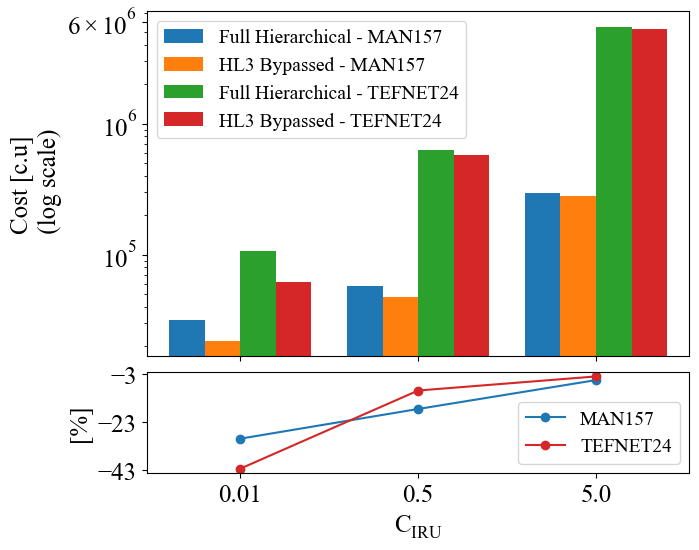

In [ ]:
fig = plt.figure(figsize=(7, 6))
gs = gridspec.GridSpec(2, 1, height_ratios=[1.7, 0.5], wspace=0.18, hspace = 0.07)
bar_width = 0.2
axs = [fig.add_subplot(gs[0]),
       fig.add_subplot(gs[1])]

TCO_TEFNET_400G = np.array([TCO_TEFNET_IRU_0v01_400G, TCO_TEFNET_IRU_0v5_400G, TCO_TEFNET_IRU_5_400G])
TCO_MAN157_400G = np.array([TCO_MAN157_IRU_0v01_400G, TCO_MAN157_IRU_0v5_400G, TCO_MAN157_IRU_5_400G])
C_IRU_List = [0.01, 0.5, 5.0]
x = np.arange(len(C_IRU_List))

axs[0].bar(x - 3 * bar_width / 2, TCO_MAN157_400G[:, 0],
        width=bar_width, label='Full Hierarchical - MAN157')

axs[0].bar(x - bar_width / 2, TCO_MAN157_400G[:, 1],
        width=bar_width, label='HL3 Bypassed - MAN157')

axs[0].bar(x + bar_width / 2, TCO_TEFNET_400G[:, 0],
        width=bar_width, label='Full Hierarchical - TEFNET24')

axs[0].bar(x + 3 * bar_width / 2, TCO_TEFNET_400G[:, 1],
        width=bar_width, label='HL3 Bypassed - TEFNET24')

axs[0].set_xticks(x)
axs[0].set_xticklabels([])
axs[0].set_yscale('log')
axs[0].set_ylabel('Cost [c.u]\n (log scale)', fontsize=18)
axs[0].tick_params(axis='x', labelsize=18)
axs[0].tick_params(axis='y', labelsize=18)
axs[0].set_yticks([1e5, 1e6, 6e6])
axs[0].set_yticklabels([r'$10^5$', r'$10^6$', r'$6 \times 10^6$'])
axs[0].legend(loc='upper left', fontsize=14)

axs[1].plot(x, safe_percent_diff(TCO_MAN157_400G[:, 0], TCO_MAN157_400G[:, 1]), '-o', color = 'C0', label = 'MAN157')
axs[1].plot(x, safe_percent_diff(TCO_TEFNET_400G[:, 0], TCO_TEFNET_400G[:, 1]), '-o', color = 'C3', label = 'TEFNET24')
axs[1].set_ylabel('[%]', fontsize = 18)
axs[1].tick_params(axis = 'x', labelsize = 18)
axs[1].set_xticks(x)
axs[1].set_xticklabels(C_IRU_List)
axs[1].set_xlabel(r'$C_{IRU}$', fontsize = 18)
axs[1].tick_params(axis='y', labelsize = 18)
axs[1].legend(loc='lower right', fontsize=14)
axs[1].set_yticks(np.arange(-43, 0, 20))

for ax in axs:
    ax.set_xlim(x.min() - 1.5 * width, x.max() + 1.5 * width)
    
plt.tight_layout()
# plt.savefig(save_directory /
#             f"{network_noBypass.topology_name}_Cost_Comparison_With_TEFNET24.png",
#             format='png', dpi=600, bbox_inches='tight')
plt.show()

In [78]:
safe_percent_diff(TCO_MAN157_400G[:, 0], TCO_MAN157_400G[:, 1])

array([-29.90131987, -17.47080825,  -5.37238047])

In [79]:
safe_percent_diff(TCO_TEFNET_400G[:, 0], TCO_TEFNET_400G[:, 1])

array([-42.45846994,  -9.74081366,  -3.84486428])

#### *ENERGY PLOT*

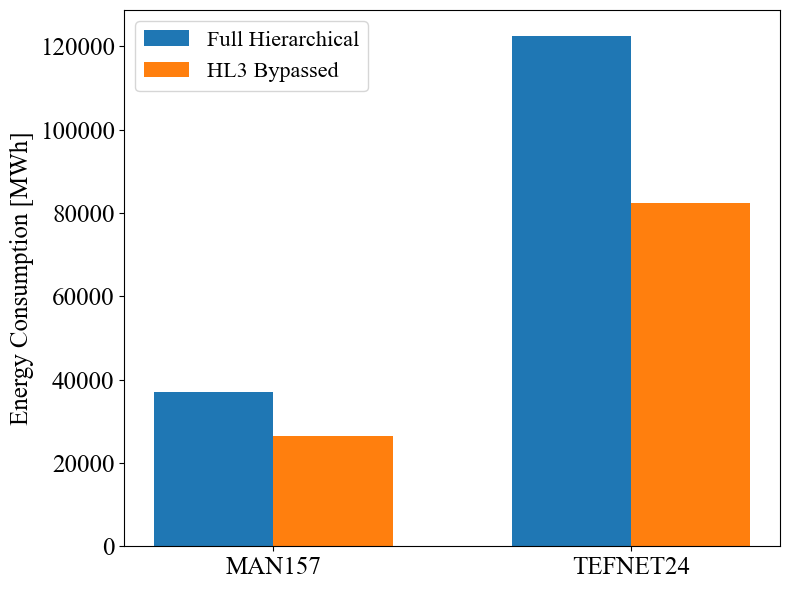

In [57]:
fig, axs = plt.subplots(figsize=(8, 6))
bar_width = 0.2

x  = [0, 0.6]

axs.bar(x[1] - bar_width / 2, ENERGY_TEFNET_400G[0],
        width=bar_width, label='Full Hierarchical', color = 'C0')

axs.bar(x[1] + bar_width / 2, ENERGY_TEFNET_400G[1],
        width=bar_width, label='HL3 Bypassed', color = 'C1')

axs.bar(x[0] - bar_width / 2, ENERGY_MAN157_400G[0],
        width=bar_width, color = 'C0')

axs.bar(x[0] + bar_width / 2, ENERGY_MAN157_400G[1],
        width=bar_width, color = 'C1')

axs.set_xticks(x)
axs.set_ylabel('Energy Consumption [MWh]', fontsize=18)
axs.tick_params(axis='x', labelsize=18)
axs.tick_params(axis='y', labelsize=18)
axs.set_xticklabels([str(c) for c in ["MAN157", "TEFNET24"]], fontsize=18)
axs.legend(fontsize=16)

plt.tight_layout()
# plt.savefig(save_directory /
#             f"{network_noBypass.topology_name}_Energy_Comparison_With_TEFNET24.png",
#             format='png', dpi=600, bbox_inches='tight')
fig.show()

In [58]:
safe_percent_diff(ENERGY_MAN157_400G[0], ENERGY_MAN157_400G[1])

array(-28.296039)

In [59]:
safe_percent_diff(ENERGY_TEFNET_400G[0], ENERGY_TEFNET_400G[1])

array(-32.77905432)

### *Sensitivity Analysis on CAGR*

In [60]:
CAGR_List = [0.2, 0.3, 0.4, 0.5, 0.6]

TCO_MAN157_CAGRs_FH = np.array([33311.78302558275, 41540.65432043262, 57726.48965875169, 86397.33690727812, 135592.95264889608])
TCO_MAN157_CAGRs_HL3Bypassed = np.array([30830.803194974935, 36799.13873178595, 47641.20533931985, 69484.44371970324, 106468.50391247383])

ENERGY_MAN157_CAGRs_FH = np.array([13187.470440000001, 21492.2658, 36986.47638, 61408.497899999995, 99710.06928])
ENERGY_MAN157_CAGRs_HL3Bypassed = np.array([9569.279460000002, 15870.864300000001, 26520.768600000003, 44043.75138, 71896.74078000001])

TCO_TEFNET24_CAGRs_FH = np.array([469975.20264537097, 529825.4512935525, 635948.447575206, 806203.1499074935, 1047082.3363756735])
TCO_TEFNET24_CAGRs_HL3Bypassed = np.array([449745.3655783412, 477901.87860597036, 574001.8943176214, 746574.1614020135, 1002611.2124318186])

ENERGY_TEFNET24_CAGRs_FH = np.array([48743.41692, 81056.05443, 122600.78586, 214375.52592, 362949.98115])
ENERGY_TEFNET24_CAGRs_HL3Bypassed = np.array([34982.063550000006, 57002.47851000001, 82413.40767, 144469.65063000002, 245641.84493999998])

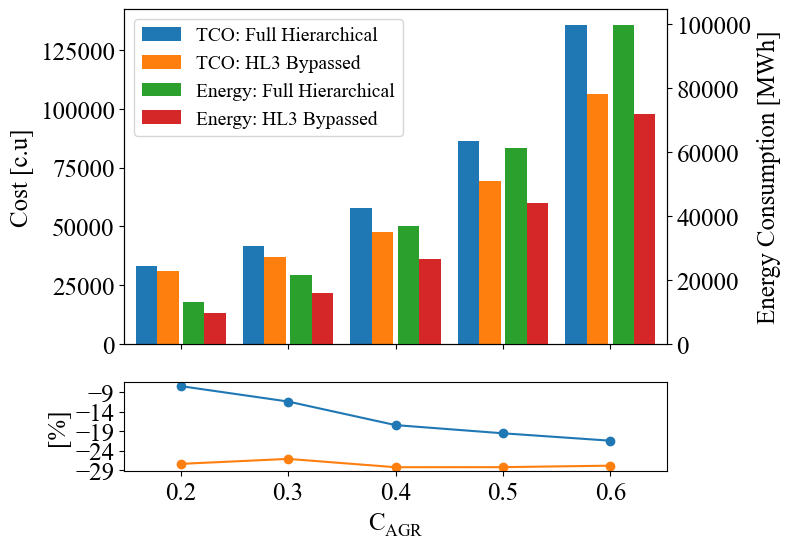

In [61]:
fig = plt.figure(figsize=(7, 6))
gs = gridspec.GridSpec(2, 1, height_ratios=[1.5, 0.4], wspace=0.18, hspace = 0.18)
bar_width = 0.2
delta = 0.02
axs = [fig.add_subplot(gs[0]),
       fig.add_subplot(gs[1])]

# 1. Create the secondary y-axis
axs2 = axs[0].twinx()

x = np.arange(len(CAGR_List))

axs[0].bar(x - 3 * bar_width / 2 - delta, TCO_MAN157_CAGRs_FH,
        width=bar_width, label='TCO: Full Hierarchical')

axs[0].bar(x - bar_width / 2 - delta, TCO_MAN157_CAGRs_HL3Bypassed,
        width=bar_width, label='TCO: HL3 Bypassed')

# axs[0].set_xlabel('CAGR', fontsize=18)
axs[0].set_ylabel('Cost [c.u]', fontsize=18)
axs[0].tick_params(axis='x', labelsize=18)
axs[0].tick_params(axis='y', labelsize=18)
axs[0].set_xticks(x)
axs[0].set_xticklabels([])
# axs.set_yticks(np.arange(0, max(norm_noBypass.max(), norm_bypass.max())+5, 5))

axs[1].plot(x, safe_percent_diff(TCO_MAN157_CAGRs_FH, TCO_MAN157_CAGRs_HL3Bypassed), '-o', color = 'C0', label = 'Rel Diff of Cost')
axs[1].set_ylabel('[%]', fontsize = 18)
axs[1].tick_params(axis = 'x', labelsize = 18)
axs[1].set_xticks(x)
axs[1].set_xticklabels(CAGR_List)
axs[1].set_xlabel(r'$C_{IRU}$', fontsize = 18)
axs[1].tick_params(axis='y', labelsize = 18)
axs[1].set_yticks(np.arange(-23, -5, 4))

for ax in axs:
    ax.set_xlim(x.min() - 1.5 * width, x.max() + 1.5 * width)
    
axs2.bar(x + bar_width / 2 + delta, ENERGY_MAN157_CAGRs_FH,
        width=bar_width, label='Energy: Full Hierarchical', color='C2')

axs2.bar(x + 3 * bar_width / 2 + delta, ENERGY_MAN157_CAGRs_HL3Bypassed,
        width=bar_width, label='Energy: HL3 Bypassed', color='C3')

axs2.set_xticks(x)
# axs[0].set_xlabel('CAGR', fontsize=18)
axs2.set_ylabel('Energy Consumption [MWh]', fontsize=18)
axs2.tick_params(axis='x', labelsize=18)
axs2.tick_params(axis='y', labelsize=18)
axs2.set_xticks(x)
axs2.set_xticklabels([])

axs2.legend(loc='upper left', fontsize=16)

axs[1].plot(x, safe_percent_diff(ENERGY_MAN157_CAGRs_FH, ENERGY_MAN157_CAGRs_HL3Bypassed), '-o', color = 'C1', label = 'Rel Diff of Energy')
axs[1].set_ylabel('[%]', fontsize = 18)
axs[1].tick_params(axis = 'x', labelsize = 18)
axs[1].set_xticks(x)
axs[1].set_xticklabels(CAGR_List)
axs[1].set_xlabel(r'$C_{AGR}$', fontsize = 18)
axs[1].tick_params(axis='y', labelsize = 18)
axs[1].set_yticks(np.arange(-29, -6, 5))
# axs[1].legend(loc='upper right', fontsize=16, ncol = 2, framealpha=1)

for ax in axs:
    ax.set_xlim(x.min() - 1.5 * width, x.max() + 1.5 * width)
    
plt.tight_layout()

# 5. Combine the legends from both axes into one
handles1, labels1 = axs[0].get_legend_handles_labels()
handles2, labels2 = axs2.get_legend_handles_labels()
axs2.legend(handles1 + handles2, labels1 + labels2, loc='upper left', fontsize=14)

# plt.savefig(save_directory /
#             f"{network_noBypass.topology_name}_Cost_Energy_Comparison_With_Different_CAGRs.png",
#             format='png', dpi=600, bbox_inches='tight')
plt.show()

In [62]:
safe_percent_diff(TCO_MAN157_CAGRs_FH, TCO_MAN157_CAGRs_HL3Bypassed)

array([ -7.44775453, -11.41415721, -17.47080825, -19.57571123,
       -21.47932335])

In [63]:
safe_percent_diff(ENERGY_MAN157_CAGRs_FH, ENERGY_MAN157_CAGRs_HL3Bypassed)

array([-27.43658078, -26.1554624 , -28.296039  , -28.27743246,
       -27.89420236])

### *1000Gbps and 400Gbps BVT Comparison in MAN157*

In [64]:
TCO_MAN157_noBypass = np.array([57726.48965875169, # 400G
                       55137.22558126199 # 1000G
                       ])

TCO_MAN157_HL3Bypassed = np.array([47641.20533931985, # 400G
                          45690.454999999994 # 1000G
                          ])

ENERGY_MAN157_noBypass = np.array([36986.47638, # 400G
                            33104.94228 # 1000G
                            ])

ENERGY_MAN157_HL3Bypassed = np.array([26520.768600000003, # 400G
                            23625.312659999996 # 1000G
                            ])

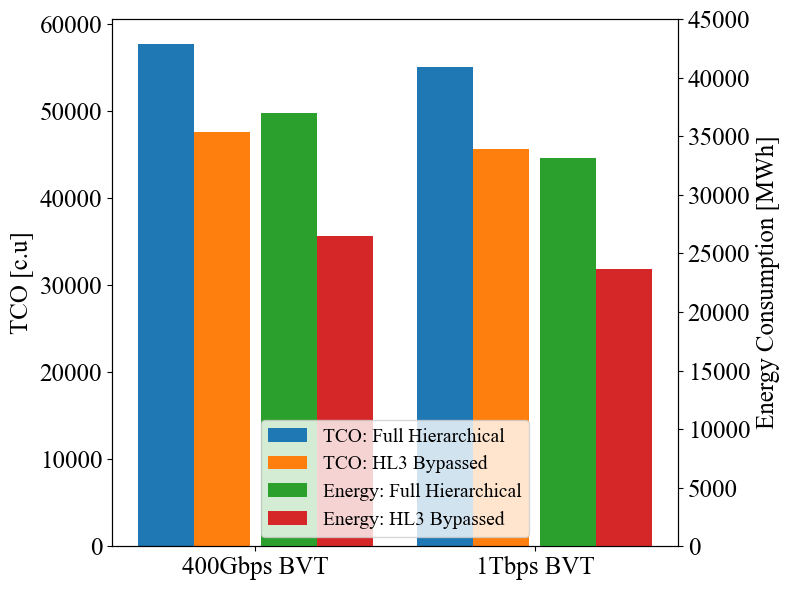

In [65]:
# Assuming numpy as np, pyplot as plt, and your data variables are already defined
x_labels = ['400Gbps BVT', '1Tbps BVT']
x = np.arange(len(x_labels))

fig, axs = plt.subplots(figsize=(8, 6))

# 1. Create the secondary y-axis
axs2 = axs.twinx()

bar_width = 0.2
delta = 0.02

# 2. Plot TCO on the primary axis (axs)
# Tip: Added distinct labels and colors to differentiate TCO from Energy
axs.bar(x - 3 * bar_width / 2 - delta, TCO_MAN157_noBypass,
        width=bar_width, label='TCO: Full Hierarchical', color='C0')

axs.bar(x - bar_width / 2 - delta, TCO_MAN157_HL3Bypassed,
        width=bar_width, label='TCO: HL3 Bypassed', color='C1')

# 3. Plot Energy on the secondary axis (axs2)
axs2.bar(x + bar_width / 2 + delta, ENERGY_MAN157_noBypass,
        width=bar_width, label='Energy: Full Hierarchical', color='C2')

axs2.bar(x + 3 * bar_width / 2 + delta, ENERGY_MAN157_HL3Bypassed,
        width=bar_width, label='Energy: HL3 Bypassed', color='C3')

# Set x-axis properties
axs.set_xticks(x)
axs.set_xticklabels(x_labels, fontsize=18)
axs.set_xlabel('', fontsize=18)
axs.tick_params(axis='x', labelsize=18)

# 4. Set y-axis properties for BOTH axes
axs.set_ylabel('TCO [c.u]', fontsize=18) 
axs.tick_params(axis='y', labelsize=18)

axs2.set_ylabel('Energy Consumption [MWh]', fontsize=18) # Fixed "Comsumption" typo
axs2.set_yticks(np.arange(0, 50000, 5000))
axs2.tick_params(axis='y', labelsize=18)

# 5. Combine the legends from both axes into one
handles1, labels1 = axs.get_legend_handles_labels()
handles2, labels2 = axs2.get_legend_handles_labels()
axs2.legend(handles1 + handles2, labels1 + labels2, loc='lower center', fontsize=14)

rel_diff = safe_percent_diff(ENERGY_MAN157_CAGRs_FH, ENERGY_MAN157_CAGRs_HL3Bypassed)

plt.tight_layout()
# plt.savefig(save_directory /
#             f"{network_noBypass.topology_name}_Cost_Energy_Comparison_1000Gvs400G.png",
#             format='png', dpi=600, bbox_inches='tight')
plt.show()

In [66]:
safe_percent_diff(ENERGY_MAN157_noBypass, ENERGY_MAN157_HL3Bypassed)


array([-28.296039 , -28.6350888])

In [67]:
safe_percent_diff(TCO_MAN157_noBypass, TCO_MAN157_HL3Bypassed)


array([-17.47080825, -17.133199  ])

### *Sensitivity Analysis of Ref Year in Router Selection*

In [68]:
IP_Cost_Cum_noBypass_Ref_5 = np.load(results_noBypass_dir / 'MAN157_IP_Cost_Power_noBypass_RefYear_5.npz')['IP_Cost_Cum']
IP_Cost_Cum_noBypass_Ref_4 = np.load(results_noBypass_dir / 'MAN157_IP_Cost_Power_noBypass_RefYear_4.npz')['IP_Cost_Cum']
IP_Cost_Cum_noBypass_Ref_3 = np.load(results_noBypass_dir / 'MAN157_IP_Cost_Power_noBypass_RefYear_3.npz')['IP_Cost_Cum']
IP_Cost_Cum_noBypass_Ref_2 = np.load(results_noBypass_dir / 'MAN157_IP_Cost_Power_noBypass_RefYear_2.npz')['IP_Cost_Cum']

IP_Cost_Cum_HL3Bypassed_Ref_5 = np.load(results_HL3Bypassed_dir / 'MAN157_IP_Cost_Power_HL3Bypassed_RefYear_5.npz')['IP_Cost_Cum']
IP_Cost_Cum_HL3Bypassed_Ref_4 = np.load(results_HL3Bypassed_dir / 'MAN157_IP_Cost_Power_HL3Bypassed_RefYear_4.npz')['IP_Cost_Cum']
IP_Cost_Cum_HL3Bypassed_Ref_3 = np.load(results_HL3Bypassed_dir / 'MAN157_IP_Cost_Power_HL3Bypassed_RefYear_3.npz')['IP_Cost_Cum']
IP_Cost_Cum_HL3Bypassed_Ref_2 = np.load(results_HL3Bypassed_dir / 'MAN157_IP_Cost_Power_HL3Bypassed_RefYear_2.npz')['IP_Cost_Cum']



IP_Energy_Cum_noBypass_Ref_5 = np.load(results_noBypass_dir / 'MAN157_IP_Cost_Power_noBypass_RefYear_5.npz')['IP_Power_Cum'] * 365 * 24 / 1e6
IP_Energy_Cum_noBypass_Ref_4 = np.load(results_noBypass_dir / 'MAN157_IP_Cost_Power_noBypass_RefYear_4.npz')['IP_Power_Cum'] * 365 * 24 / 1e6
IP_Energy_Cum_noBypass_Ref_3 = np.load(results_noBypass_dir / 'MAN157_IP_Cost_Power_noBypass_RefYear_3.npz')['IP_Power_Cum'] * 365 * 24 / 1e6
IP_Energy_Cum_noBypass_Ref_2 = np.load(results_noBypass_dir / 'MAN157_IP_Cost_Power_noBypass_RefYear_2.npz')['IP_Power_Cum'] * 365 * 24 / 1e6

IP_Energy_Cum_HL3Bypassed_Ref_5 = np.load(results_HL3Bypassed_dir / 'MAN157_IP_Cost_Power_HL3Bypassed_RefYear_5.npz')['IP_Power_Cum'] * 365 * 24 / 1e6
IP_Energy_Cum_HL3Bypassed_Ref_4 = np.load(results_HL3Bypassed_dir / 'MAN157_IP_Cost_Power_HL3Bypassed_RefYear_4.npz')['IP_Power_Cum'] * 365 * 24 / 1e6
IP_Energy_Cum_HL3Bypassed_Ref_3 = np.load(results_HL3Bypassed_dir / 'MAN157_IP_Cost_Power_HL3Bypassed_RefYear_3.npz')['IP_Power_Cum'] * 365 * 24 / 1e6
IP_Energy_Cum_HL3Bypassed_Ref_2 = np.load(results_HL3Bypassed_dir / 'MAN157_IP_Cost_Power_HL3Bypassed_RefYear_2.npz')['IP_Power_Cum'] * 365 * 24 / 1e6

In [69]:
TCO_noBypass.sum()

np.float64(51193.68965875169)

In [70]:
TCO_HL3Bypassed.sum()

np.float64(42830.005339319854)

In [71]:
TCO_Final_noBypass_Ref_5 = TCO_noBypass.sum() + IP_Cost_Cum_noBypass_Ref_5[-1]
TCO_Final_noBypass_Ref_4 = TCO_noBypass.sum() + IP_Cost_Cum_noBypass_Ref_4[-1]
TCO_Final_noBypass_Ref_3 = TCO_noBypass.sum() + IP_Cost_Cum_noBypass_Ref_3[-1]
TCO_Final_noBypass_Ref_2 = TCO_noBypass.sum() + IP_Cost_Cum_noBypass_Ref_2[-1]

TCO_Final_HL3Bypassed_Ref_5 = TCO_HL3Bypassed.sum() + IP_Cost_Cum_HL3Bypassed_Ref_5[-1]
TCO_Final_HL3Bypassed_Ref_4 = TCO_HL3Bypassed.sum() + IP_Cost_Cum_HL3Bypassed_Ref_4[-1]
TCO_Final_HL3Bypassed_Ref_3 = TCO_HL3Bypassed.sum() + IP_Cost_Cum_HL3Bypassed_Ref_3[-1]
TCO_Final_HL3Bypassed_Ref_2 = TCO_HL3Bypassed.sum() + IP_Cost_Cum_HL3Bypassed_Ref_2[-1]

In [72]:
ENERGY_Final_noBypass_Ref_5 = energy_consumption_annual_noBypass.sum() + IP_Energy_Cum_noBypass_Ref_5[-1]
ENERGY_Final_noBypass_Ref_4 = energy_consumption_annual_noBypass.sum() + IP_Energy_Cum_noBypass_Ref_4[-1]
ENERGY_Final_noBypass_Ref_3 = energy_consumption_annual_noBypass.sum() + IP_Energy_Cum_noBypass_Ref_3[-1]
ENERGY_Final_noBypass_Ref_2 = energy_consumption_annual_noBypass.sum() + IP_Energy_Cum_noBypass_Ref_2[-1]

ENERGY_Final_HL3Bypassed_Ref_5 = energy_consumption_annual_HL3Bypassed.sum() + IP_Energy_Cum_HL3Bypassed_Ref_5[-1]
ENERGY_Final_HL3Bypassed_Ref_4 = energy_consumption_annual_HL3Bypassed.sum() + IP_Energy_Cum_HL3Bypassed_Ref_4[-1]
ENERGY_Final_HL3Bypassed_Ref_3 = energy_consumption_annual_HL3Bypassed.sum() + IP_Energy_Cum_HL3Bypassed_Ref_3[-1]
ENERGY_Final_HL3Bypassed_Ref_2 = energy_consumption_annual_HL3Bypassed.sum() + IP_Energy_Cum_HL3Bypassed_Ref_2[-1]

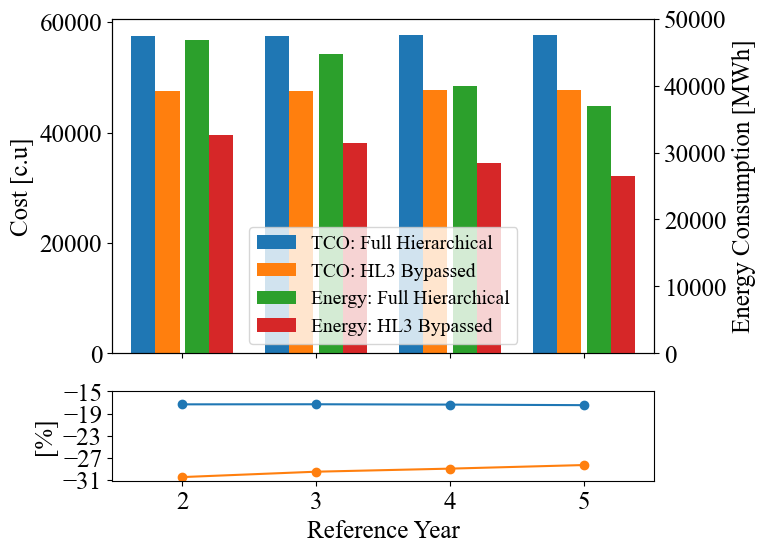

In [73]:
fig = plt.figure(figsize=(7, 6))
gs = gridspec.GridSpec(2, 1, height_ratios=[1.5, 0.4], wspace=0.18, hspace = 0.18)
bar_width = 0.18
delta = 0.02
axs = [fig.add_subplot(gs[0]),
       fig.add_subplot(gs[1])]

# 1. Create the secondary y-axis
axs2 = axs[0].twinx()

Ref_years_list = [2, 3, 4, 5]
x = np.arange(len(Ref_years_list))

nobypass_cost_values = np.array(
    [TCO_Final_noBypass_Ref_2, 
     TCO_Final_noBypass_Ref_3, 
     TCO_Final_noBypass_Ref_4, 
     TCO_Final_noBypass_Ref_5]
)

bypass_cost_values = np.array(
    [TCO_Final_HL3Bypassed_Ref_2, 
     TCO_Final_HL3Bypassed_Ref_3, 
     TCO_Final_HL3Bypassed_Ref_4, 
     TCO_Final_HL3Bypassed_Ref_5]
)

axs[0].bar(x - 3 * bar_width / 2 - delta, nobypass_cost_values,
        width=bar_width, label='TCO: Full Hierarchical')

axs[0].bar(x - bar_width / 2 - delta, bypass_cost_values,
        width=bar_width, label='TCO: HL3 Bypassed')


axs[0].set_ylabel('Cost [c.u]', fontsize=18)
axs[0].tick_params(axis='x', labelsize=18)
axs[0].tick_params(axis='y', labelsize=18)
axs[0].set_xticks(x)
axs[0].set_xticklabels([])

axs[1].plot(x, safe_percent_diff(nobypass_cost_values, bypass_cost_values), '-o', color = 'C0', label = 'Rel Diff of Cost')
axs[1].set_ylabel('[%]', fontsize = 18)
axs[1].tick_params(axis = 'x', labelsize = 18)
axs[1].set_xticks(x)
axs[1].set_xticklabels(Ref_years_list)
axs[1].set_xlabel('Reference Year', fontsize = 18)
axs[1].tick_params(axis='y', labelsize = 18)
axs[1].set_yticks(np.arange(-17.5, -16.8, 0.1))

for ax in axs:
    ax.set_xlim(x.min() - 1.5 * width, x.max() + 1.5 * width)

nobypass_energy_values = np.array(
    [ENERGY_Final_noBypass_Ref_2, 
     ENERGY_Final_noBypass_Ref_3, 
     ENERGY_Final_noBypass_Ref_4, 
     ENERGY_Final_noBypass_Ref_5]
)

bypass_energy_values = np.array(
    [ENERGY_Final_HL3Bypassed_Ref_2, 
     ENERGY_Final_HL3Bypassed_Ref_3, 
     ENERGY_Final_HL3Bypassed_Ref_4, 
     ENERGY_Final_HL3Bypassed_Ref_5]
)
   
axs2.bar(x + bar_width / 2 + delta, nobypass_energy_values,
        width=bar_width, label='Energy: Full Hierarchical', color='C2')

axs2.bar(x + 3 * bar_width / 2 + delta, bypass_energy_values,
        width=bar_width, label='Energy: HL3 Bypassed', color='C3')

axs2.set_ylabel('Energy Consumption [MWh]', fontsize=18)
axs2.tick_params(axis='x', labelsize=18)
axs2.tick_params(axis='y', labelsize=18)
axs2.set_yticks(np.arange(0, 50000 + 1, 10000))

# 5. Combine the legends from both axes into one
handles1, labels1 = axs[0].get_legend_handles_labels()
handles2, labels2 = axs2.get_legend_handles_labels()
axs2.legend(handles1 + handles2, labels1 + labels2, loc='lower center', fontsize=14)

axs[1].plot(x, safe_percent_diff(nobypass_energy_values, bypass_energy_values), '-o', color = 'C1', label = 'Rel Diff of Energy')
axs[1].set_ylabel('[%]', fontsize = 18)
axs[1].tick_params(axis = 'x', labelsize = 18)
axs[1].set_xticks(x)
axs[1].set_xticklabels(Ref_years_list)
axs[1].set_xlabel('Reference Year', fontsize = 18)
axs[1].tick_params(axis='y', labelsize = 18)
axs[1].set_yticks(np.arange(-31, -14, 4))
# axs[1].legend(loc='upper right', fontsize=16, ncol = 2, framealpha=1)

for ax in axs:
    ax.set_xlim(x.min() - 1.5 * width, x.max() + 1.5 * width)
    
plt.tight_layout()

# 5. Combine the legends from both axes into one
handles1, labels1 = axs[0].get_legend_handles_labels()
handles2, labels2 = axs2.get_legend_handles_labels()
axs2.legend(handles1 + handles2, labels1 + labels2, loc='lower center', fontsize=14)

# plt.savefig(save_directory /
#             f"{network_noBypass.topology_name}_Cost_Energy_Comparison_With_Different_RefYears.png",
#             format='png', dpi=600, bbox_inches='tight')
plt.show()

In [74]:
safe_percent_diff(nobypass_cost_values, bypass_cost_values)

array([-17.32389272, -17.30834654, -17.36905916, -17.47080825])

In [75]:
safe_percent_diff(nobypass_energy_values, bypass_energy_values)

array([-30.47280758, -29.49917334, -28.94539572, -28.296039  ])